# Exploration Notebook

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

SEED = 42

## Dataset Overview

#### Load Data

In [2]:
train = pd.read_csv("data/raw/train.csv")
test = pd.read_csv("data/raw/test.csv")
clientes = pd.read_csv("data/raw/clientes.csv")

#### Dimensions and Structure

In [4]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Clientes shape:", clientes.shape)

Train shape: (6534, 40)
Test shape: (986, 38)
Clientes shape: (1143, 13)


In [5]:
total = len(train) + len(test)

print(f"Train : {len(train):>6,} rows ({len(train) / total * 100:6.2f}%)")
print(f"Test  : {len(test):>6,} rows ({len(test) / total * 100:6.2f}%)")
print(f"Total : {total:>6,} rows (100.00%)")

Train :  6,534 rows ( 86.89%)
Test  :    986 rows ( 13.11%)
Total :  7,520 rows (100.00%)


In [6]:
print("\nTrain first 5 rows:")
display(train.head())

print("\nTest first 5 rows:")
display(test.head())

print("\nClientes first 5 rows:")
display(clientes.head())


Train first 5 rows:


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890



Test first 5 rows:


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,286.37,582.05,232.82,53.55,0.0,0.0,349.23,104.409267,22,1,...,519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000006,0.621602
1,1949.25,1725.00,1725.00,224.25,0.0,0.0,0.00,0.000000,1,1,...,942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,10000008,-1.318874
2,2738.71,4114.83,2738.71,0.00,0.0,0.0,1376.12,1019.466586,99,1,...,386654,Maybe Tomorrow Payment 4,VLOOKUP Master 1,Decorative Dashboard Zone 2,Maybe Tomorrow Delivery 54,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000010,1.251905
3,726.98,591.04,591.04,135.94,0.0,0.0,0.00,341.649008,39,2,...,588088,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 35,Final Excel Warehouse 1,Ctrl Z Series 2,2025-11-05,10000020,0.988362
4,670.76,555.49,545.33,125.43,0.0,0.0,10.16,326.715748,13,1,...,610152,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 1,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 2,2026-07-12,10000025,0.511535



Clientes first 5 rows:


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


load data, dimensions, data types, missing values, train/test schema

In [7]:
display(test.head())

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,286.37,582.05,232.82,53.55,0.0,0.0,349.23,104.409267,22,1,...,519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000006,0.621602
1,1949.25,1725.00,1725.00,224.25,0.0,0.0,0.00,0.000000,1,1,...,942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,10000008,-1.318874
2,2738.71,4114.83,2738.71,0.00,0.0,0.0,1376.12,1019.466586,99,1,...,386654,Maybe Tomorrow Payment 4,VLOOKUP Master 1,Decorative Dashboard Zone 2,Maybe Tomorrow Delivery 54,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000010,1.251905
3,726.98,591.04,591.04,135.94,0.0,0.0,0.00,341.649008,39,2,...,588088,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 35,Final Excel Warehouse 1,Ctrl Z Series 2,2025-11-05,10000020,0.988362
4,670.76,555.49,545.33,125.43,0.0,0.0,10.16,326.715748,13,1,...,610152,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 1,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 2,2026-07-12,10000025,0.511535


In [8]:
print("\nTrain columns:")
print(train.columns.tolist())

print("\nColumns in train but not in test:")
print(set(train.columns) - set(test.columns))

print("\nColumns in test but not in train:")
print(set(test.columns) - set(train.columns))

print("\nClientes columns:")
print(clientes.columns.tolist())


Train columns:
['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'repeat_purchase_90d', 'spend_next_90d', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise']

Columns in train but not in test:
{'spend_next_90d', 'repeat_purchase_90d'}

Columns in test but not in train:
set()

Clientes columns:
['customer_id', 'country_or_region', 'commercial_region', 'island'

#### Identify Data Types

In [9]:
data_types = pd.DataFrame({
    "data_type": train.dtypes.astype(str),
    "total_entries": len(train),
    "unique_values": train.nunique(dropna=True),
    "missing_values": train.isna().sum(),
    "missing_percentage": ((train.isna().sum() / train.shape[0]) * 100).round(2)
})

In [10]:
display(data_types)

,data_type,total_entries,unique_values,missing_values,missing_percentage
Total a Pagar,float64,6534,6122,65,0.99
Total Bruto,float64,6534,6038,65,0.99
Total Liquido,float64,6534,6093,65,0.99
Total Imp_,float64,6534,5406,65,0.99
Total Portes,float64,6534,215,65,0.99
Total Desc_ Global,float64,6534,109,65,0.99
Total Desc_ Linha,float64,6534,3519,65,0.99
Custo,float64,6534,5736,65,0.99
N_ Detalhes,float64,6534,171,65,0.99
invoice_count_current_purchase,float64,6534,5,65,0.99


Interpretation(train):

- A recurring group of 65 missing values

> Many purchase-related variables, such as Total a Pagar, Custo, customer_tenure_days, and spend_90d, have exactly 65 missing values.

>This suggests that the missing values may correspond to the same 65 rows. If so, a shared cause, such as incomplete records or a particular data-processing step, could explain them.

- Some features have substantial missingness

> spent_next_90d - 47.58%.

> This target-like variable has 3,109 missing values. Before deciding how to handle them, determine whether these represent unavailable future observations, customers without future purchases, or a data-generation issue.

- Historical customer features have varying missingness

> prior_std_gap_days has 22.62% missingness, while prior_mean_gap_days has 20.02% and prior_std_purchase_value has 17.03%.

>These features may be undefined for customers with too few previous purchases, rather than missing due to a data-quality problem.

In [11]:
data_types_test = pd.DataFrame({
    "data_type": test.dtypes.astype(str),
    "total_entries": len(test),
    "unique_values": test.nunique(dropna=True),
    "missing_values": test.isna().sum(),
    "missing_percentage": ((test.isna().sum() / test.shape[0]) * 100).round(2)
})

In [12]:
display(data_types_test)

,data_type,total_entries,unique_values,missing_values,missing_percentage
Total a Pagar,float64,986,970,0,0.00
Total Bruto,float64,986,972,0,0.00
Total Liquido,float64,986,971,0,0.00
Total Imp_,float64,986,873,0,0.00
Total Portes,float64,986,37,0,0.00
Total Desc_ Global,float64,986,34,0,0.00
Total Desc_ Linha,float64,986,818,0,0.00
Custo,float64,986,951,0,0.00
N_ Detalhes,int64,986,112,0,0.00
invoice_count_current_purchase,int64,986,3,0,0.00


Interpretation(test):

- Missing values are generally low

> Most variables have no missing values, including Total a Pagar, Total Bruto, Total Líquido, Custo, customer_tenure_days, and the majority of historical spending features.

> This suggests that the dataset is relatively complete, with no major missing-data issues.

- Historical customer features have varying missingness

> prior_mean_gap_days has the highest missingness (7.71%, 76 values), followed by prior_std_gap_days (7.00%, 69 values).

> days_since_previous_purchase and prior_mean_purchase_value both have 5.27% missingness (52 values), while prior_std_purchase_value has 4.67% (46 values).

> These missing values may be associated with customers who have insufficient purchase history to calculate meaningful statistics.

- A recurring group of 30 missing values

> Several variables, including spend_365d, payment_type, salesperson, transport_method, and warehouse, have exactly 30 missing values (3.04%).

> This may indicate that the missing values occur in the same observations, potentially due to incomplete transaction records or a shared data-processing issue.

- Some historical purchase statistics have very low missingness

> prior_min_purchase_value and prior_max_purchase_value each have 22 missing values (2.23%).

> These missing values should be investigated to determine whether they represent customers without sufficient historical transactions.

- Potentially irrelevant or low-information features

> document_series has only 1 unique value, providing no variability and therefore little predictive value.

> ID and random_noise each have 986 unique values, suggesting that ID is a record identifier and random_noise may be an artificially generated feature.

> These variables should be evaluated for removal before model training.

In [13]:
data_types_costumers = pd.DataFrame({
    "data_type": clientes.dtypes.astype(str),
    "total_entries": len(clientes),
    "unique_values": clientes.nunique(dropna=True),
    "missing_values": clientes.isna().sum(),
    "missing_percentage": ((clientes.isna().sum() / clientes.shape[0]) * 100).round(2)
})

In [14]:
display(data_types_costumers)

,data_type,total_entries,unique_values,missing_values,missing_percentage
customer_id,int64,1143,1143,0,0.00
country_or_region,str,1143,11,0,0.00
commercial_region,str,1143,37,114,9.97
island,str,1143,10,578,50.57
municipality,str,1143,183,159,13.91
city,str,1143,417,546,47.77
postal_area,str,1143,271,71,6.21
postal_code,str,1143,828,170,14.87
street,str,1143,511,598,52.32
address,str,1143,1120,6,0.52


The `customer_id` column functions perfectly as a primary key, containing 1,143 unique values with no missing entries, ensuring a safe merge with the transaction tables without the risk of unintended row duplication. In contrast, the `customer_type` variable is entirely null (100% missing values) and should therefore be removed from the dataset immediately. Regarding geographical information, there is significant data sparsity: granular variables such as `island`, `city`, and `street` have approximately 50% missing values, suggesting that the modelling process should rely on broader geographical aggregations, such as `country_or_region` (0% missing values) and `commercial_region` (9.97% missing values). Finally, a minor anomaly is observed in `company_name`, which contains 1,141 unique values across 1,143 records, indicating that some companies may appear more than once or that multiple branches share the same name under different IDs.

##### Analyze whether the same 65 rows are missing(train)

In [15]:
cols_65 = train.columns[train.isna().sum() == 65]
missing_65 = train[cols_65].isna()
reference = missing_65.iloc[:, 0]
same_pattern = missing_65.eq(reference, axis=0).all().all()

print("Number of columns:", len(cols_65))
print("Rows with any missing value:", missing_65.any(axis=1).sum())
print("Rows missing all selected columns:", missing_65.all(axis=1).sum())
print("Identical missing pattern:", same_pattern)

Number of columns: 24
Rows with any missing value: 65
Rows missing all selected columns: 65
Identical missing pattern: True


All 24 columns have missing values in exactly the same 65 rows.

In [16]:
cols_65 = train.columns[train.isna().sum() == 65]

affected_mask = train[cols_65].isna().all(axis=1)
affected_rows = train.loc[affected_mask]

print("Affected rows:", len(affected_rows))
print("Unique customers:", affected_rows["customer_id"].nunique())

other_cols = train.columns.difference(cols_65)

display(
    affected_rows[other_cols].head(20)
)

Affected rows: 65
Unique customers: 53


,ID,customer_id,days_since_previous_purchase,payment_type,prior_max_purchase_value,prior_mean_gap_days,prior_mean_purchase_value,prior_min_purchase_value,prior_std_gap_days,prior_std_purchase_value,repeat_purchase_90d,salesperson,spend_365d,spend_next_90d,transport_method,warehouse
393,10000457,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN
484,10000560,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN
582,10000678,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN
583,10000679,508217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
748,10000870,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
762,10000890,670446,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
817,10000955,248523,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN
837,10000980,561391,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
839,10000983,334782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN
954,10001116,793048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN


- `ID` and `customer_id` are populated. These rows are not entirely empty records.

- Several groups of features are missing together.

- The target variables remain populated.

In [17]:
cols_65 = train.columns[train.isna().sum() == 65]
affected_mask = train[cols_65].isna().all(axis=1)

comparison = pd.DataFrame({
    "Affected (65 rows)": train.loc[affected_mask, "repeat_purchase_90d"],
    "Other rows": train.loc[~affected_mask, "repeat_purchase_90d"]
})

summary = pd.DataFrame({
    "Affected rows": [
        affected_mask.sum(),
        train.loc[affected_mask, "repeat_purchase_90d"].mean() * 100
    ],
    "Other rows": [
        (~affected_mask).sum(),
        train.loc[~affected_mask, "repeat_purchase_90d"].mean() * 100
    ]
}, index=["Number of rows", "Repeat purchase rate (%)"])

display(summary.round(2))

,Affected rows,Other rows
Number of rows,65.00,6469.00
Repeat purchase rate (%),50.77,55.97


##### Analyze whether the same 30 rows are missing(test)

In [18]:
cols_30 = test.columns[test.isna().sum() == 30]
missing_30 = test[cols_30].isna()
reference = missing_30.iloc[:, 0]
same_pattern = missing_30.eq(reference, axis=0).all().all()

print("Number of columns:", len(cols_30))
print("Rows with any missing value:", missing_30.any(axis=1).sum())
print("Rows missing all selected columns:", missing_30.all(axis=1).sum())
print("Identical missing pattern:", same_pattern)

Number of columns: 5
Rows with any missing value: 145
Rows missing all selected columns: 0
Identical missing pattern: False


These results alone do not confirm a shared pattern of missingness or a common data-processing issue. 

##### Analyze the different number of customers and company name (customers)

In [19]:

duplicated_companies = clientes[clientes.duplicated(subset=['company_name'], keep=False)]

columns_comparison = [
    'customer_id', 
    'company_name', 
    'country_or_region', 
    'commercial_region', 
    'city', 
    'customer_since_year'
]

# Mostrar os resultados ordenados pelo nome da empresa para ser fácil comparar visualmente
display(duplicated_companies[columns_comparison].sort_values(by='company_name'))

,customer_id,company_name,country_or_region,commercial_region,city,customer_since_year
390,255774,Excel Is Not A Database Ltd 384,Country CT10: Land of The Final Version,Region RG17: We Will See Later,NaN,2021
391,714679,Excel Is Not A Database Ltd 384,Country CT10: Land of The Final Version,Region RG17: We Will See Later,NaN,2017
998,652673,Excel Is Not A Database Ltd 664,Country CT10: Land of The Final Version,Region RG33: We Will See Later,City CY378: Duplicate Row Moor,2015
999,821383,Excel Is Not A Database Ltd 664,Country CT10: Land of The Final Version,NaN,NaN,2015


- **Case 1: Possible new account or branch — "Excel Is Not A Database Ltd 384"**  
  IDs 255774 and 714679 share the same commercial region but have different registration years (2017 and 2021). This may indicate a reactivation, a new contract, or a separate branch rather than a data error.

- **Case 2: Likely duplicate — "Excel Is Not A Database Ltd 664"**  
  IDs 652673 and 821383 were both registered in 2015 in the same country. One record has complete geographical information, while the other lacks region and city data, suggesting a possible duplicate entry with an incomplete profile.

##### Conclusion of the Missing Values Analysis

The missing-value analysis identified 65 transactions (0.99% of the dataset) with a shared missingness pattern across 24 features. These records retain their `repeat_purchase_90d` target, with an observed repeat-purchase rate of 50.77%, compared with 55.97% among the remaining transactions. Although the affected group exhibits a 5.20% lower repeat-purchase rate, this descriptive difference does not establish a statistically significant association. The underlying cause of the missingness should be investigated before deciding whether to exclude these observations or apply an imputation strategy.

## Data Quality and Identifiers

#### Duplicates

In [20]:
print("Exact duplicate rows in train:", train.duplicated().sum())
print("Exact duplicate rows in test:", test.duplicated().sum())
print("Exact duplicate rows in clientes:", clientes.duplicated().sum())

for name, df in [("train", train), ("test", test)]:
    if "ID" in df.columns:
        print(
            f"{name}: duplicate ID values =",
            df["ID"].duplicated().sum()
        )

if "ID" in train.columns and "ID" in test.columns:
    overlapping_ids = set(train["ID"].dropna()) & set(test["ID"].dropna())
    print("IDs appearing in both train and test:", len(overlapping_ids))

Exact duplicate rows in train: 0
Exact duplicate rows in test: 0
Exact duplicate rows in clientes: 0
train: duplicate ID values = 0
test: duplicate ID values = 0
IDs appearing in both train and test: 0


#### Invalid Values

##### Negative Values

In [21]:
for name, df in [("train", train), ("test", test)]:
    numerical_cols = df.select_dtypes(include=[np.number]).columns
    cols_to_check = [c for c in numerical_cols if c not in ["ID", "customer_id", "random_noise"]]

    negative_dict = {}
    for col in cols_to_check:
        negative_count = (df[col] < 0).sum()
        if negative_count > 0:
            negative_dict[col] = negative_count

    if negative_dict:
        df_negatives = pd.DataFrame(list(negative_dict.items()), columns=["Column", "Negative Count"])
        df_negatives.insert(0, "DataFrame", name)
        df_negatives["Percentage"] = (df_negatives["Negative Count"] / len(df) * 100).round(2)
        display(df_negatives.sort_values(by="Negative Count", ascending=False))
    else:
        continue

,DataFrame,Column,Negative Count,Percentage
0,train,days_since_previous_purchase,16,0.24
1,train,prior_mean_purchase_value,16,0.24
2,train,prior_mean_gap_days,16,0.24
3,train,spend_365d,15,0.23


,DataFrame,Column,Negative Count,Percentage
0,test,days_since_previous_purchase,2,0.2
1,test,prior_mean_purchase_value,2,0.2
2,test,prior_mean_gap_days,2,0.2
3,test,spend_365d,2,0.2


##### Mathematical validation of Total to Pay

In [22]:
for name, df in [("train", train), ("test", test)]:
    calculate_sum = df["Total Liquido"] + df["Total Imp_"] + df["Total Portes"]
    diference = calculate_sum - df["Total a Pagar"]
    mathematical_errors = (diference.abs() > 0.05).sum()
    print(f"Mathematical errors in {name}: {mathematical_errors} rows ({mathematical_errors / len(df) * 100:.2f}%)")

    if mathematical_errors > 0:
        inconsistent_mask = diference.abs() > 0.05
        columns_facture = ['Total a Pagar', 'Total Liquido', 'Total Imp_', 'Total Portes']
        display(df.loc[inconsistent_mask, columns_facture].head(20))

Mathematical errors in train: 1053 rows (16.12%)


,Total a Pagar,Total Liquido,Total Imp_,Total Portes
6,122.83,100.43,22.40,3.05
10,195.39,158.85,36.54,4.05
20,187.18,152.18,35.00,5.90
23,73.57,69.71,3.86,5.40
27,41.38,33.64,7.74,4.89
29,586.07,476.48,109.59,4.20
31,77.74,63.83,13.91,3.35
46,265.16,215.58,49.58,5.40
48,10.24,9.37,0.87,5.60
49,37.84,34.99,2.85,4.39


Mathematical errors in test: 69 rows (7.00%)


,Total a Pagar,Total Liquido,Total Imp_,Total Portes
14,109.96,89.40,20.56,5.40
30,327.51,266.27,61.24,8.15
38,90.75,75.34,15.41,8.34
49,332.72,270.50,62.22,7.61
55,98.28,79.90,18.38,7.40
68,118.20,96.10,22.10,7.00
72,392.91,319.44,73.47,8.15
75,89.00,72.36,16.64,5.36
80,2954.24,2401.82,552.42,30.90
85,271.65,220.85,50.80,7.85


##### Excel Errors

In [23]:
excel_errors = ["#REF!", "#N/A", "#DIV/0!", "#VALUE!", "#NAME?"]
regex_pattern = "|".join(excel_errors)

text_cols_costumers = clientes.select_dtypes(include=['object', 'string']).columns
errors_excel_dict = {}
for col in text_cols_costumers:
    error_mask = clientes[col].str.contains(regex_pattern, na=False,regex=True)
    count = error_mask.sum()
    if count > 0:
        errors_excel_dict[col] = count

if errors_excel_dict:
    print("Excel errors found in 'clientes' DataFrame:")
    display(pd.DataFrame(list(errors_excel_dict.items()), columns=["Column", "Excel Error Count"]))
    example_column = list(errors_excel_dict.keys())[0]
    print(f"\nExample of rows with Excel errors in column '{example_column}':")
    display(clientes[clientes[example_column].str.contains(regex_pattern, na=False, regex=True)][[example_column]].head(20))
else:
    print("No Excel errors found in 'clientes' DataFrame.")

Excel errors found in 'clientes' DataFrame:


,Column,Excel Error Count
0,postal_code,973



Example of rows with Excel errors in column 'postal_code':


,postal_code
0,Postal code PC828: #REF! Delivery Route
1,Postal code PC56: #REF! Delivery Route
2,Postal code PC827: #REF! Delivery Route
3,Postal code PC826: #REF! Delivery Route
4,Postal code PC826: #REF! Delivery Route
5,Postal code PC825: #REF! Delivery Route
6,Postal code PC825: #REF! Delivery Route
7,Postal code PC824: #REF! Delivery Route
8,Postal code PC824: #REF! Delivery Route
9,Postal code PC823: #REF! Delivery Route


##### Validation of Dates and cumulative windows

In [24]:
for name, df in [("train", train), ("test", test)]:
    valid_dates = pd.to_datetime(df['purchase_date'].dropna())
    print(f"Interval of valid dates in {name}: {valid_dates.min().strftime('%Y-%m-%d')} to {valid_dates.max().strftime('%Y-%m-%d')}")

    spend_violations_mask = ( 
        (df['spend_30d'] > df['spend_90d']) | (df['spend_90d'] > df['spend_180d']) | (df['spend_180d'] > df['spend_365d'])
    )
    spend_violations_count = spend_violations_mask.sum()
    print(f"Inconsistencies in spending columns(ex: spend_30d > spend_90d): {spend_violations_count}")

    if spend_violations_count > 0:
        cols_spend = ['spend_30d', 'spend_90d', 'spend_180d', 'spend_365d']
        display(df.loc[spend_violations_mask, cols_spend].head(20))

    count_violations_mask = (
        (df['purchase_count_30d'] > df['purchase_count_90d']) | (df['purchase_count_90d'] > df['purchase_count_180d']) | (df['purchase_count_180d'] > df['purchase_count_365d'])
    )
    count_violations_count = count_violations_mask.sum()
    if count_violations_count > 0:
        print(f"Inconsistencies in purchase count columns(ex: purchase_count_30d > purchase_count_90d): {count_violations_count}")


Interval of valid dates in train: 2015-07-11 to 2025-02-15
Inconsistencies in spending columns(ex: spend_30d > spend_90d): 15


,spend_30d,spend_90d,spend_180d,spend_365d
263,0.00,0.00,577.67,-3456.320000
1733,0.00,0.00,264.00,-1230.720000
1744,0.00,0.00,0.00,-167.180000
1829,0.00,0.00,0.00,-753.510000
2099,2234.61,2234.61,2234.61,-2648.440000
2851,0.00,0.00,0.00,-2169.910000
3686,177.22,177.22,420.49,-1443.640000
3690,0.00,0.00,591.02,-5133.040000
3841,467.50,3204.58,9560.84,-14740.290000
3893,0.00,0.00,179.58,-4196.900000


Interval of valid dates in test: 2025-05-24 to 2026-10-06
Inconsistencies in spending columns(ex: spend_30d > spend_90d): 2


,spend_30d,spend_90d,spend_180d,spend_365d
105,0.00,974.00,974.00,-3856.64
367,837.89,837.89,837.89,-3845.79


#### ID Analysis

In [25]:
if "ID" in train.columns:
    print("Missing ID values in train:", train["ID"].isna().sum())
    print("Unique ID values in train:", train["ID"].nunique())
    print("Total rows in train:", len(train))
    print("ID is unique in train:", train["ID"].is_unique)
    display(train["ID"].head())

else:
    print("ID column not found.")


Missing ID values in train: 0
Unique ID values in train: 6534
Total rows in train: 6534
ID is unique in train: True


0    10000000
1    10000001
2    10000002
3    10000003
4    10000004
Name: ID, dtype: int64

ID is a valid row identifier, as each row can be uniquely identified by its ID value.

#### Customer_id Analysis

Unique customers: 610
Missing customer IDs: 0


,purchase_occasions
count,610.000000
mean,10.711475
std,19.969320
min,1.000000
50%,4.000000
75%,12.000000
90%,28.000000
95%,42.550000
99%,79.460000
max,277.000000


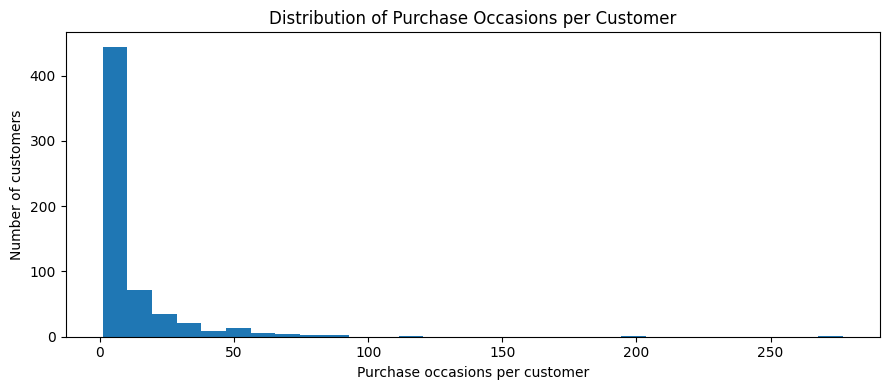

,number_of_rows,observed_repeat_rate
customer_id,,
103940,277,0.992780
258332,203,1.000000
755628,112,0.946429
151492,89,0.853933
519184,89,0.876404
239651,81,0.950617
703834,80,0.887500
227020,74,0.891892
497930,73,0.917808


In [26]:
if "customer_id" in train.columns:

    print("Unique customers:", train["customer_id"].nunique())
    print("Missing customer IDs:", train["customer_id"].isna().sum())

    purchases_per_customer = train["customer_id"].value_counts()

    display(purchases_per_customer.describe(
            percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
        ).to_frame("purchase_occasions"))

    plt.figure(figsize=(9, 4))
    plt.hist(purchases_per_customer, bins=30)
    plt.title("Distribution of Purchase Occasions per Customer")
    plt.xlabel("Purchase occasions per customer")
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.show()

    if "repeat_purchase_90d" in train.columns:

        customer_summary = (
            train.groupby("customer_id", dropna=False)
            .agg(
                number_of_rows=("repeat_purchase_90d", "size"),
                observed_repeat_rate=("repeat_purchase_90d", "mean")
            )
            .sort_values("number_of_rows", ascending=False)
        )

        display(customer_summary.head(10))

else:
    print("customer_id column not found.")

The number of records per customer varies considerably:

- The mean is 10.71 records per customer, while the median is 4.
- 75% of customers have 12 or fewer records.
- The maximum is 277 records for a single customr.

This indicates a strongly right-skewed distribution, where a relatively small number of customers account for many records.

#### Data purchase_date

In [27]:
if "purchase_date" in train.columns:

    train["purchase_date"] = pd.to_datetime(
        train["purchase_date"],
        errors="coerce"
    )

    test["purchase_date"] = pd.to_datetime(
        test["purchase_date"],
        errors="coerce"
    )

    print("Unparseable/missing train dates:",
          train["purchase_date"].isna().sum())

    print("Train date range:",
          train["purchase_date"].min(),
          "to",
          train["purchase_date"].max())

    print("Test date range:",
          test["purchase_date"].min(),
          "to",
          test["purchase_date"].max())

    if train["purchase_date"].notna().any() and test["purchase_date"].notna().any():

        print("Train latest date:", train["purchase_date"].max())

        print("Test earliest date:", test["purchase_date"].min())

else:
    print("purchase_date column not found.")

Unparseable/missing train dates: 65
Train date range: 2015-07-11 00:00:00 to 2025-02-15 00:00:00
Test date range: 2025-05-24 00:00:00 to 2026-10-06 00:00:00
Train latest date: 2025-02-15 00:00:00
Test earliest date: 2025-05-24 00:00:00


In [28]:
missing_dates = train[train["purchase_date"].isna()]
print("Genuinely missing dates:", len(missing_dates))

Genuinely missing dates: 65


The date analysis identified 65 missing or unparseable purchase dates, consistent with the 65 transactions identified in the previous missing-value analysis. The test period begins approximately 98 days after the latest training date, supporting the use of time-based validation for predictive modelling.

## Feature Exploration

#### Groups of Features

In [29]:
targets = ["repeat_purchase_90d", "spend_next_90d"]
identifiers = ["ID", "customer_id"]
date_columns = ["purchase_date"]
excluded_columns = targets + identifiers + date_columns
predictor_cols = [col for col in train.columns if col not in excluded_columns]

numeric_cols = train[predictor_cols].select_dtypes(include=[np.number]).columns.tolist()

categorical_cols = train[predictor_cols].select_dtypes(include=["object", "category", "bool", "string"]).columns.tolist()

print("Potential predictor columns:", len(predictor_cols))
print("Numeric columns:", len(numeric_cols), "->", numeric_cols)
print("Categorical columns:", len(categorical_cols), "->", categorical_cols)

Potential predictor columns: 35
Numeric columns: 29 -> ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'random_noise']
Categorical columns: 6 -> ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']


In [30]:
monetary_features = [
    "Total a Pagar",
    "Total Bruto",
    "Total Liquido",
    "Total Imp_",
    "Total Portes",
    "Total Desc_ Global",
    "Total Desc_ Linha",
    "Custo",
    "N_ Detalhes",
    "invoice_count_current_purchase",
]

historical_features = [
    "days_since_previous_purchase",
    "customer_tenure_days",
    "prior_purchase_count",
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_mean_gap_days",
    "prior_std_gap_days",
]

rolling_features = [
    "purchase_count_30d",
    "spend_30d",
    "purchase_count_90d",
    "spend_90d",
    "purchase_count_180d",
    "spend_180d",
    "purchase_count_365d",
    "spend_365d",
]

categorical_features = [
    "payment_type",
    "salesperson",
    "commercial_zone",
    "transport_method",
    "warehouse",
    "document_series",
]

other_features = [
    "random_noise",
]

feature_groups = {
    "Monetary": monetary_features,
    "Historical behaviour": historical_features,
    "Rolling behaviour": rolling_features,
    "Categorical": categorical_features,
    "Other": other_features,
}

### Monetary Variables Analysis

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,9.38,36.90,188.92,476.74,1087.67,3398.77,6543.97,22297.21
Total Bruto,6469.0,886.15,1327.64,0.83,9.23,35.00,175.74,445.74,1036.70,3251.84,6717.62,21578.28
Total Liquido,6469.0,773.34,1136.36,0.76,7.62,30.29,154.38,389.91,903.37,2838.59,5675.70,18127.81
Total Imp_,6469.0,152.22,225.26,0.00,0.00,2.28,29.93,79.74,184.84,549.12,1026.79,4169.40
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,0.00,0.00,5.75,11.80,181.06
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.85,218.49
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,0.00,0.00,13.13,92.28,540.39,1369.04,4103.44
Custo,6469.0,328.17,519.51,0.00,0.00,0.00,49.05,152.54,396.06,1227.53,2382.10,7427.40
N_ Detalhes,6469.0,21.52,27.71,1.00,1.00,1.00,4.00,11.00,29.00,75.00,128.00,423.00
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,1.00,1.00,2.00,2.00,5.00


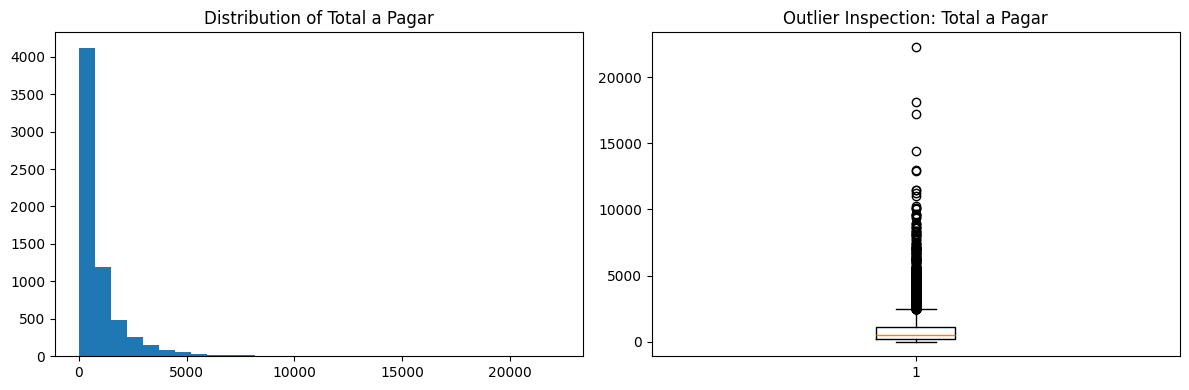

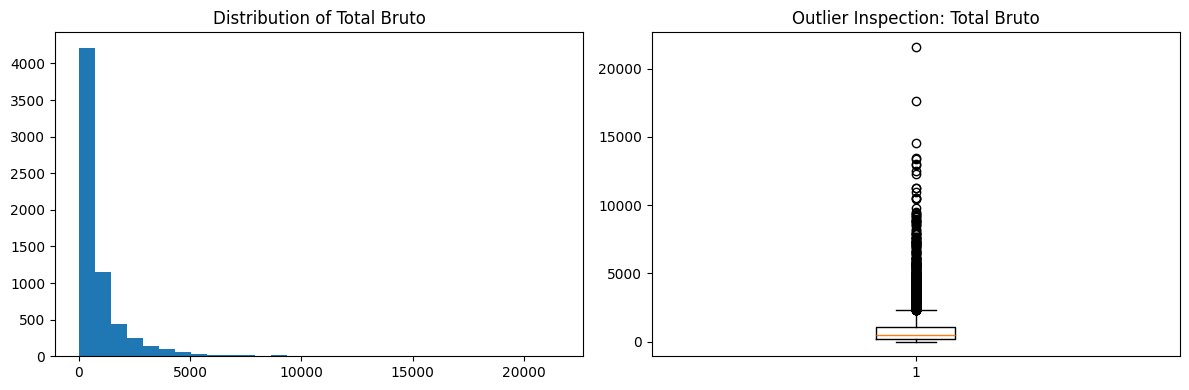

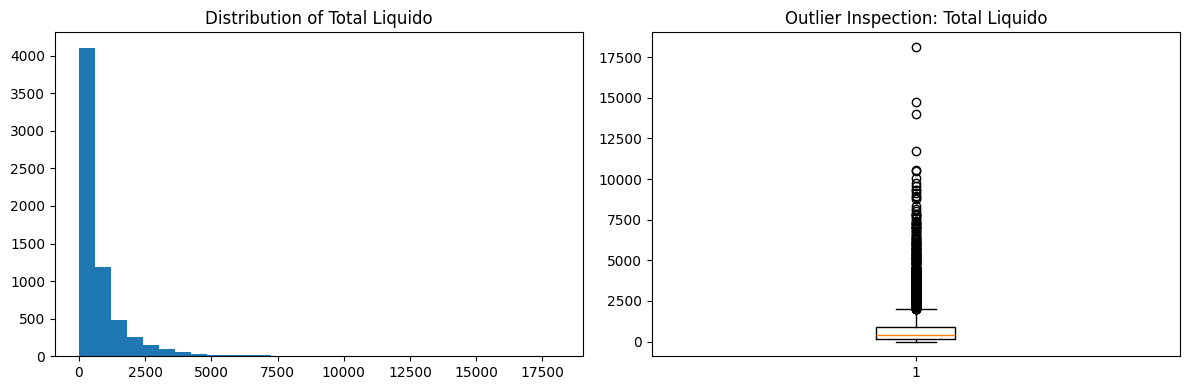

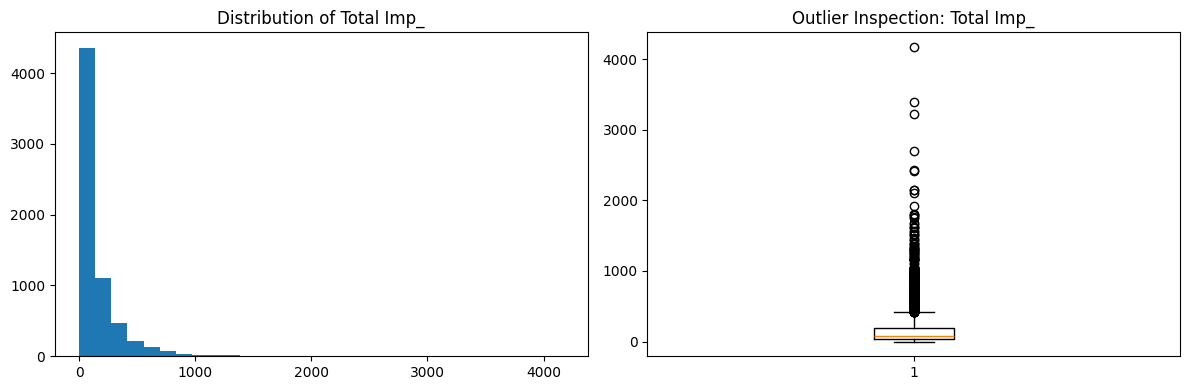

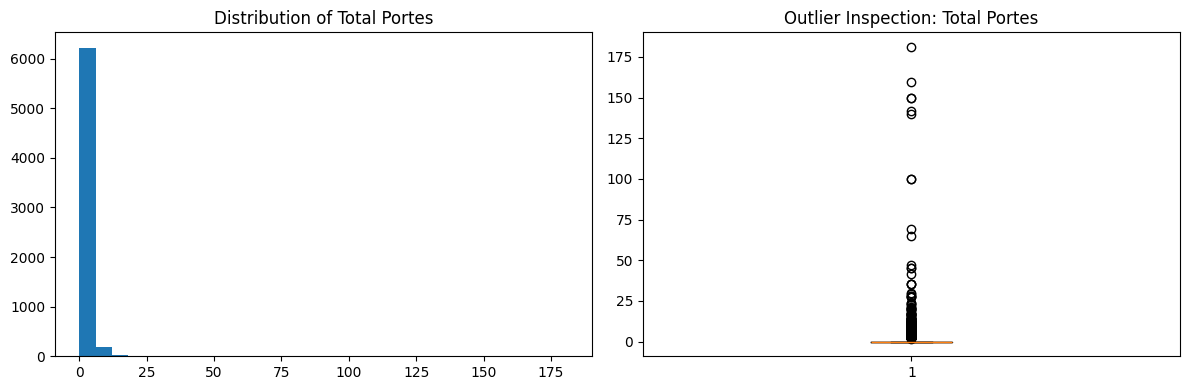

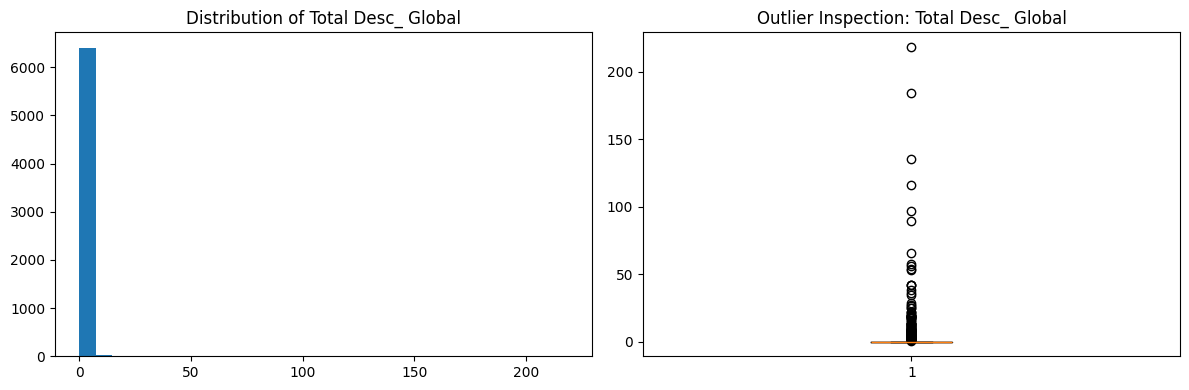

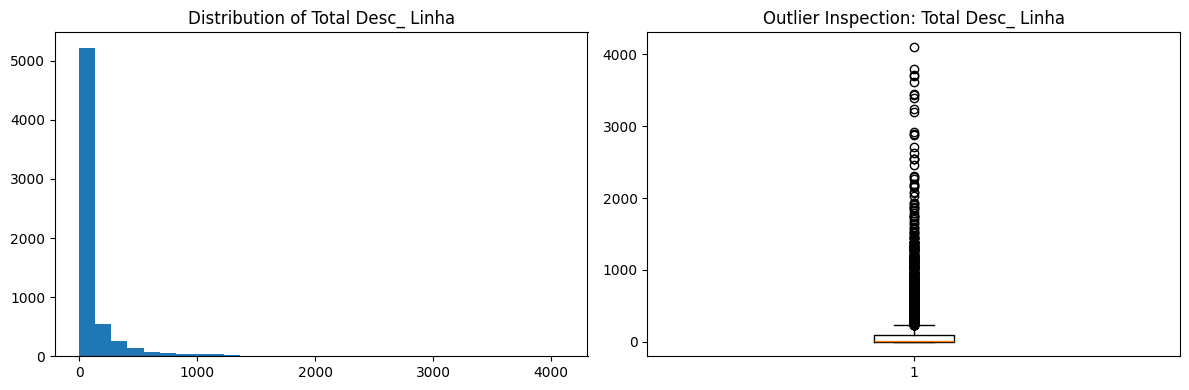

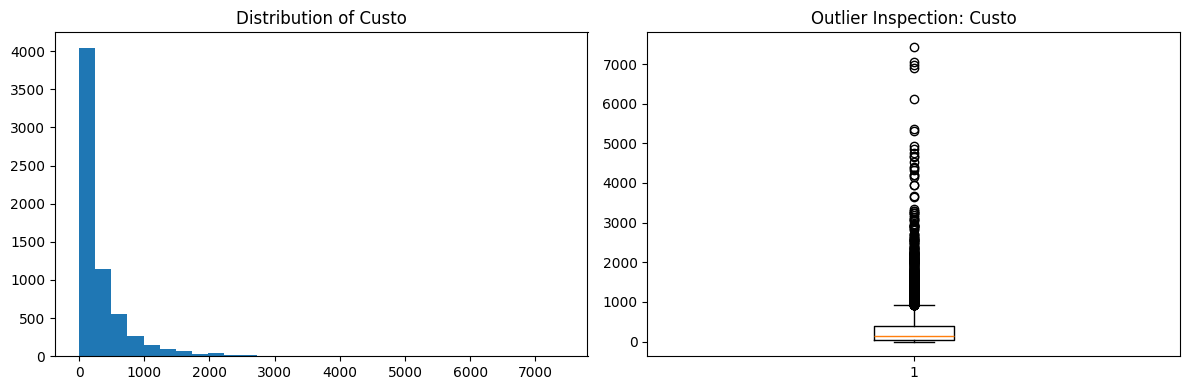

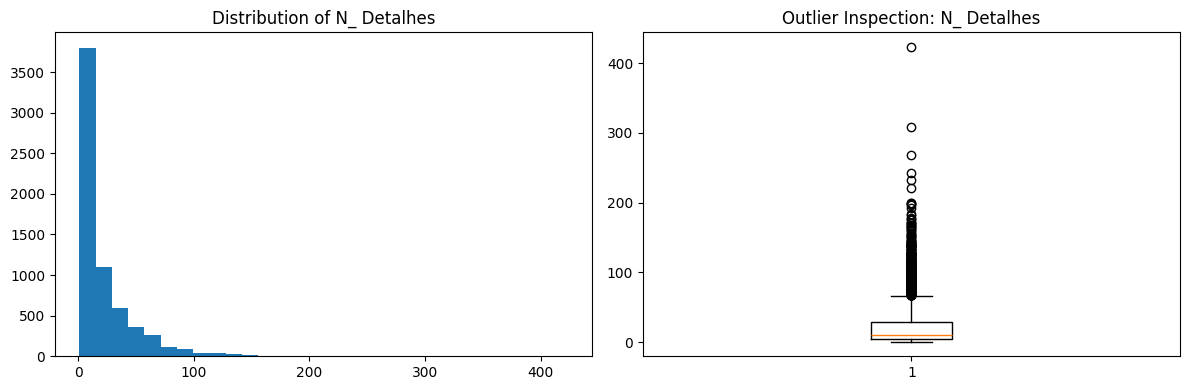

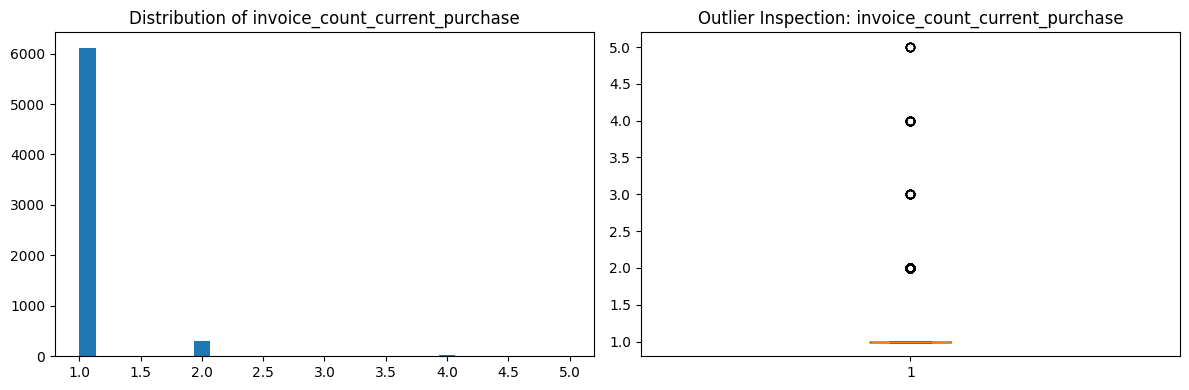

In [31]:
monetary_summary = train[monetary_features].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T.round(2)

display(monetary_summary)

for col in monetary_features:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(train[col].dropna(), bins=30)
    axes[0].set_title(f"Distribution of {col}")

    axes[1].boxplot(train[col].dropna())
    axes[1].set_title(f"Outlier Inspection: {col}")

    plt.tight_layout()
    plt.show()

- Distribution: Monetary variables are strongly right-skewed, with means higher than medians, indicating that a small number of high-value purchases influence the averages.

- Variability and outliers: Total a Pagar, Total Bruto, and Total Liquido show substantial variability and high maximum values, suggesting potential outliers.

- Discounts and shipping: Total Desc_ Global and Total Portes are zero for many transactions.

- Purchase complexity: N_ Detalhes varies considerably, reflecting differences in the number of items or transaction details.

- Invoice count: Most purchases contain a single invoice, as indicated by the median of 1 for invoice_count_current_purchase.

### Categorical Variables Analysis

In [3]:
text_columns = train.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
columns_to_ignore = ['purchase_date'] 
cat_cols = [c for c in text_columns if c not in columns_to_ignore]
print("Text columns:", len(text_columns), "->", text_columns)

Text columns: 7 -> ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date']


In [4]:
text_columns_test = test.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
cat_cols_test = [c for c in text_columns_test if c not in columns_to_ignore]
print("Text columns:", len(text_columns_test), "->", text_columns_test)

Text columns: 7 -> ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date']


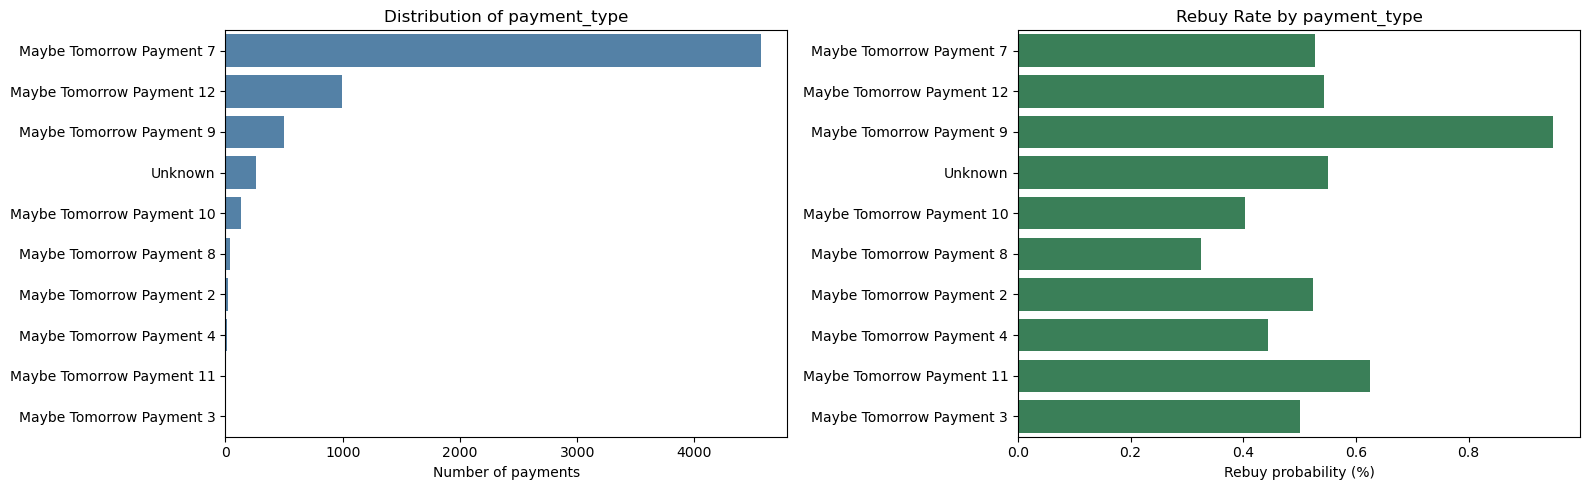

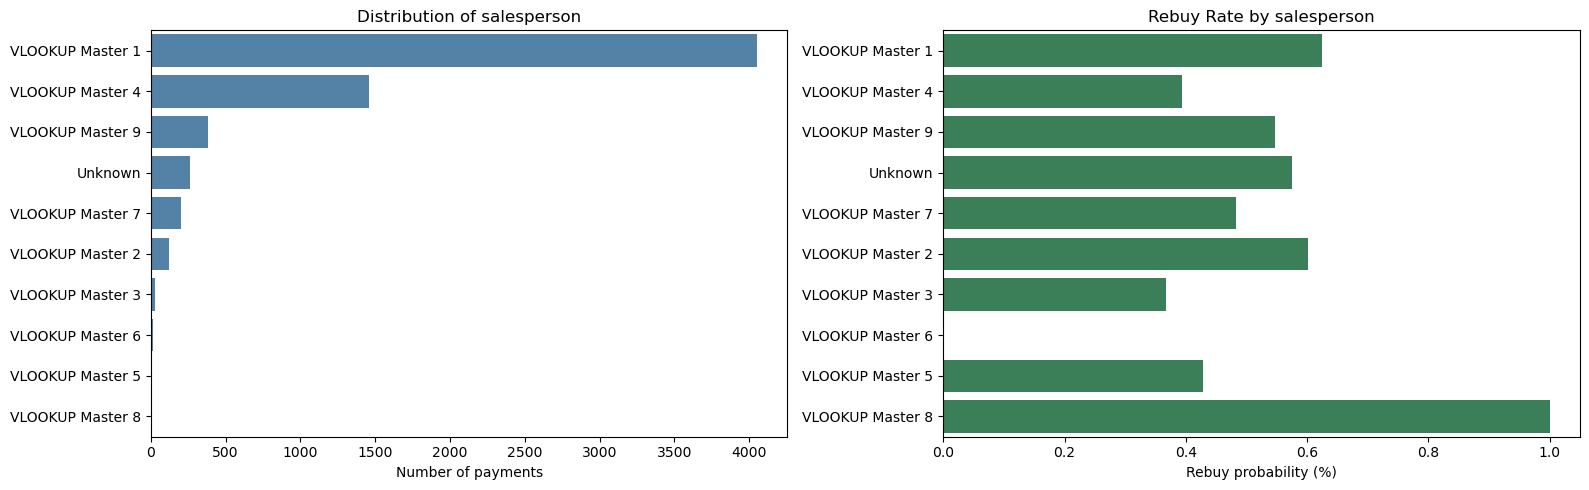

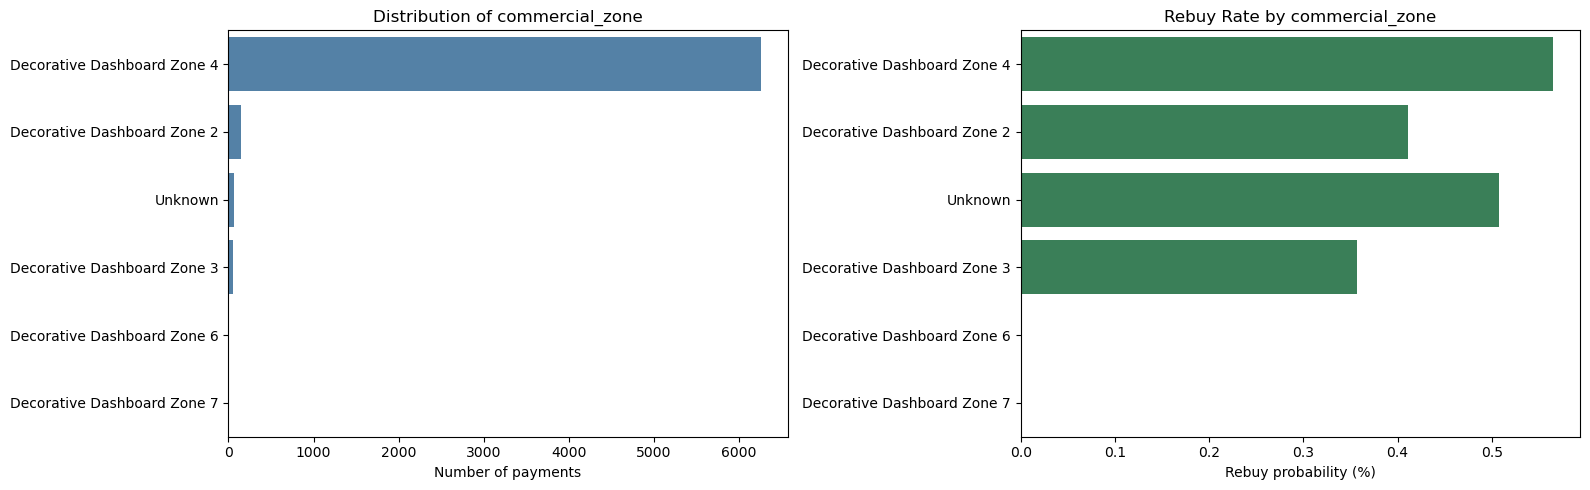

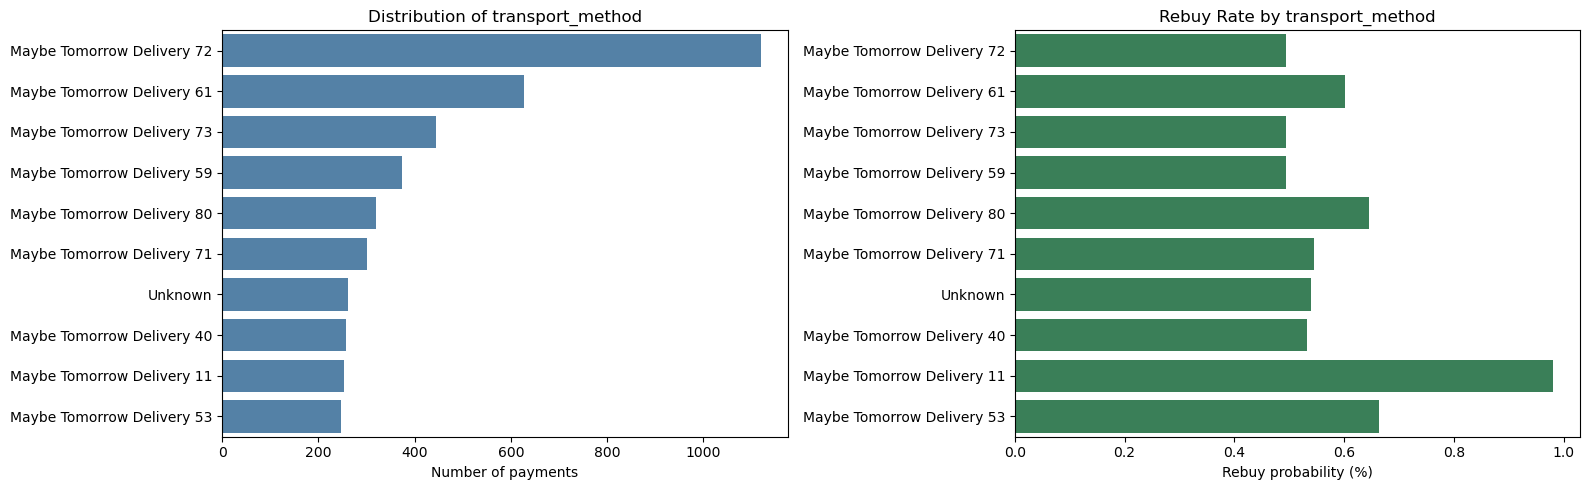

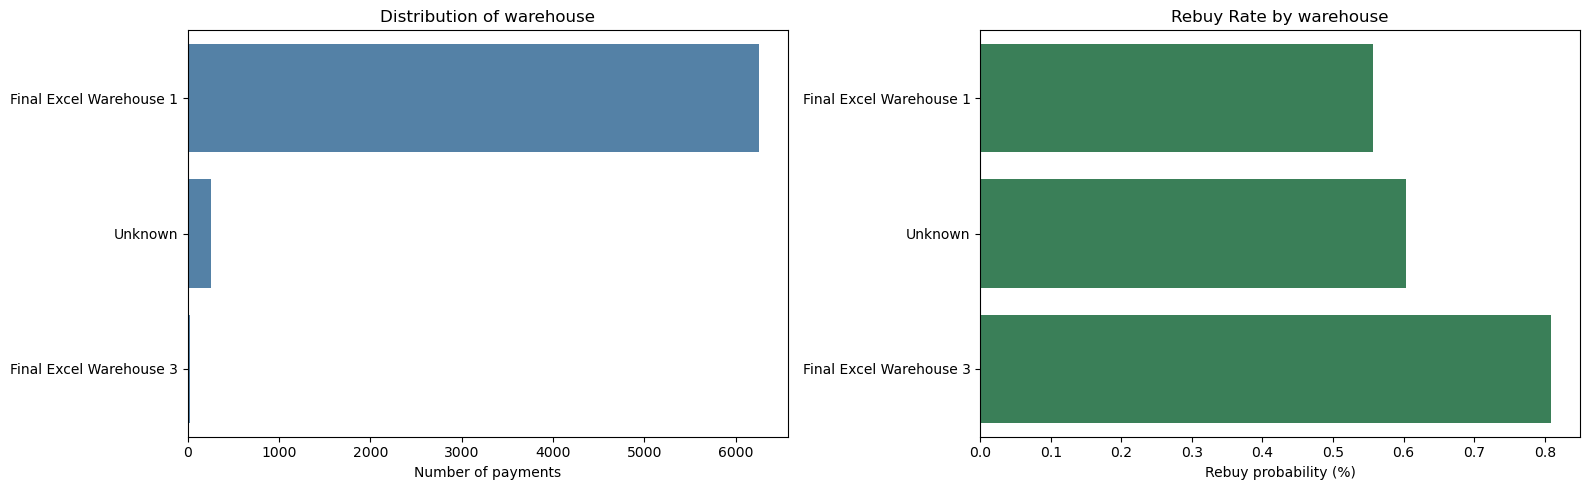

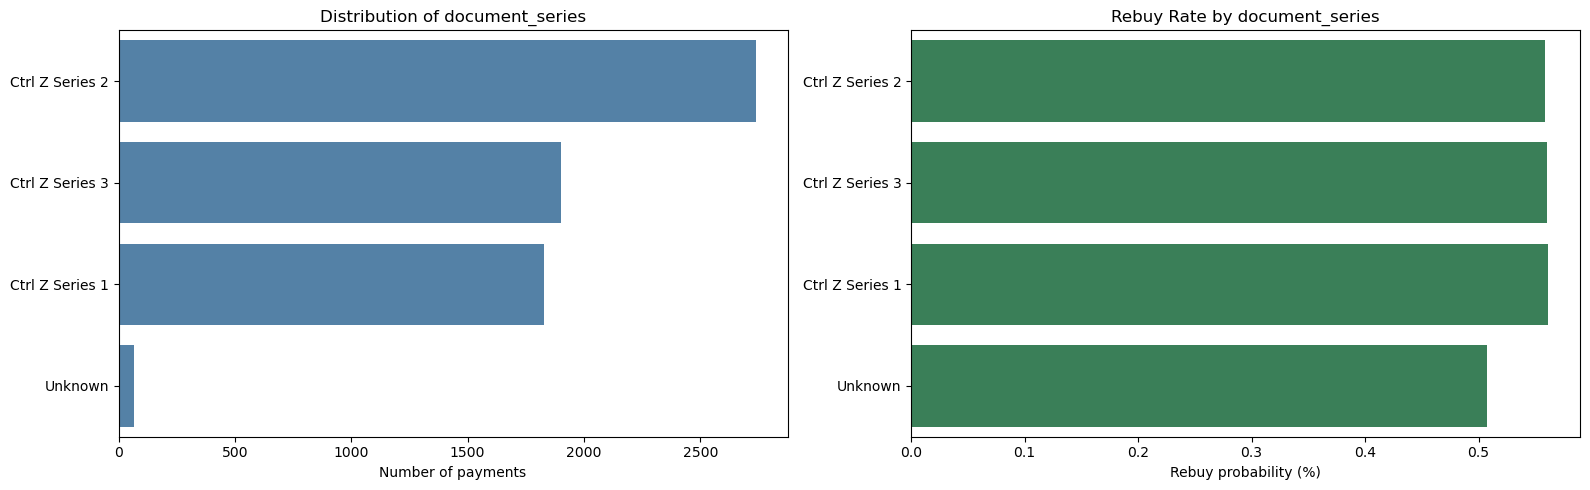

In [5]:
train_cat = train.copy()

for col in cat_cols:
    train_cat[col] = train_cat[col].fillna('Unknown')
    
    n_unique = train_cat[col].nunique()
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    if n_unique > 15:
        categories_order = train_cat[col].value_counts().head(10).index
        data_graphic = train_cat[train_cat[col].isin(categories_order)]
    else:
        categories_order = train_cat[col].value_counts().index
        data_graphic = train_cat
        
    sns.countplot(data=data_graphic, y=col, ax=axes[0], order=categories_order, color='steelblue')
    axes[0].set_title(f'Distribution of {col}')
    axes[0].set_xlabel('Number of payments')
    axes[0].set_ylabel('')
    
    sns.barplot(data=data_graphic, y=col, x='repeat_purchase_90d', ax=axes[1], 
                order=categories_order, errorbar=None, color='seagreen')
    axes[1].set_title(f'Rebuy Rate by {col}')
    axes[1].set_xlabel('Rebuy probability (%)')
    axes[1].set_ylabel('')
    
    plt.tight_layout()
    plt.show()

The bivariate analysis highlights category imbalances and differences in predictive power for `repeat_purchase_90d`.

- **Low-Variance Features**
  - `warehouse`: Almost all transactions belong to "Final Excel Warehouse 1", leaving little variation. 
  - `commercial_zone`: "Decorative Dashboard Zone 4" dominates the dataset, suggesting limited predictive value.

- **Dominant Categories and Small-Sample Effects**
  - `salesperson`: "VLOOKUP Master 1" handles most transactions, while the 100% rebuy rate for "VLOOKUP Master 8" is based on very few observations and is unlikely to be reliable.
  - `payment_type`: "Maybe Tomorrow Payment 7" dominates, whereas the high rebuy rate for "Payment 9" is based on a small sample.
  - **Recommendation:** Group rare categories into an "Other" category to reduce overfitting, where appropriate.

- **Low Predictive Signal**
  - `document_series`: Despite a relatively balanced distribution across the main series, rebuy rates remain around 55%. This suggests limited predictive value, although its usefulness should be confirmed through model evaluation.

- **Most Balanced Feature**
  - `transport_method`: The main categories have a more balanced transaction distribution and show meaningful variation in rebuy rates (approximately 50–60%+), suggesting potential predictive value.

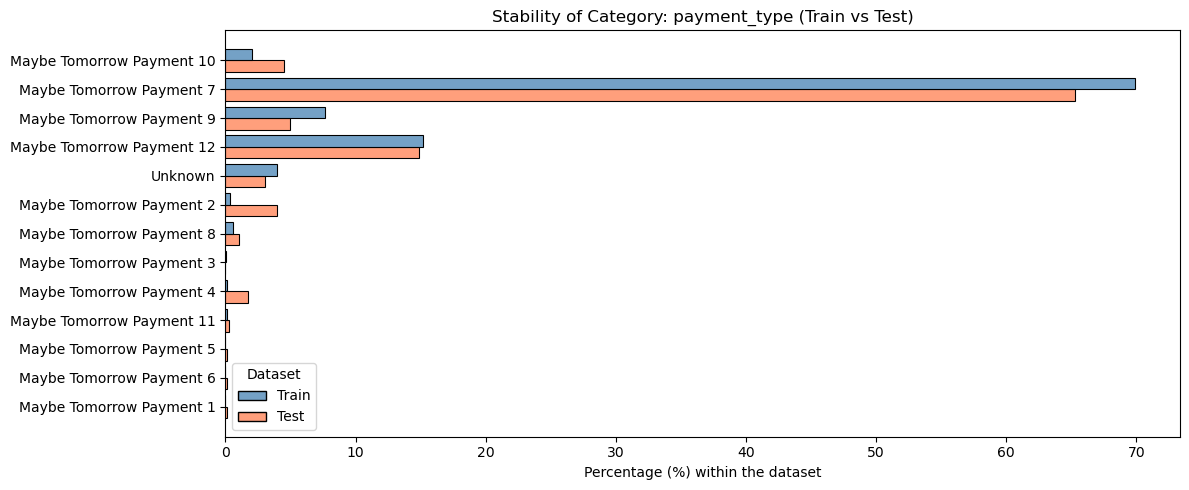

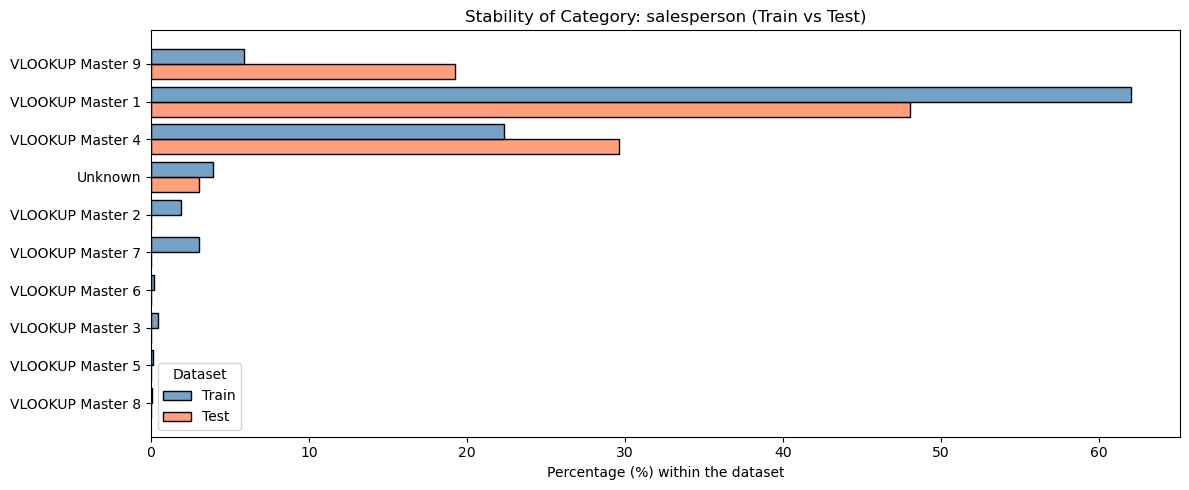

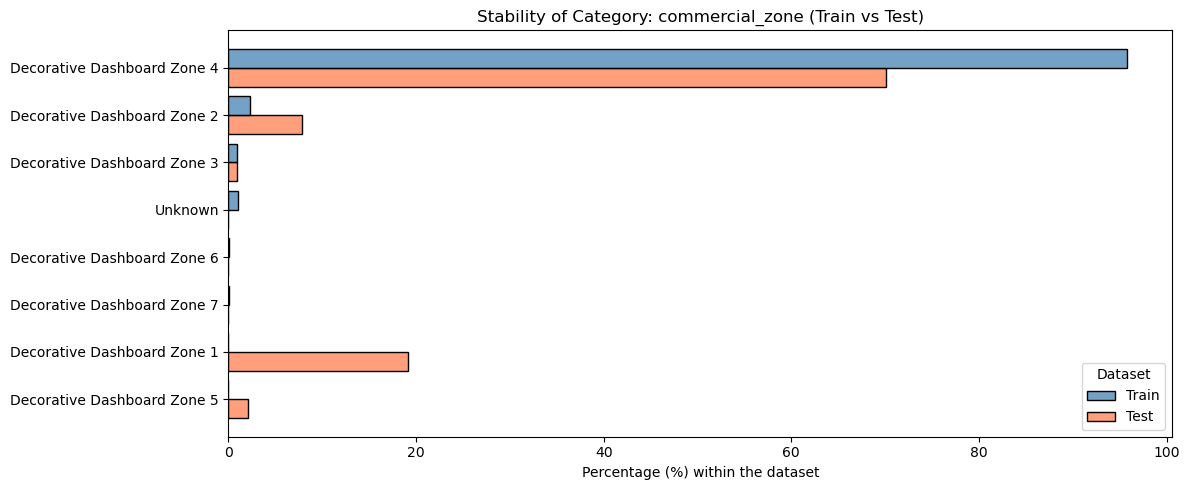


The variable 'transport_method' has 83 unique categories. Displaying only the Top 10.


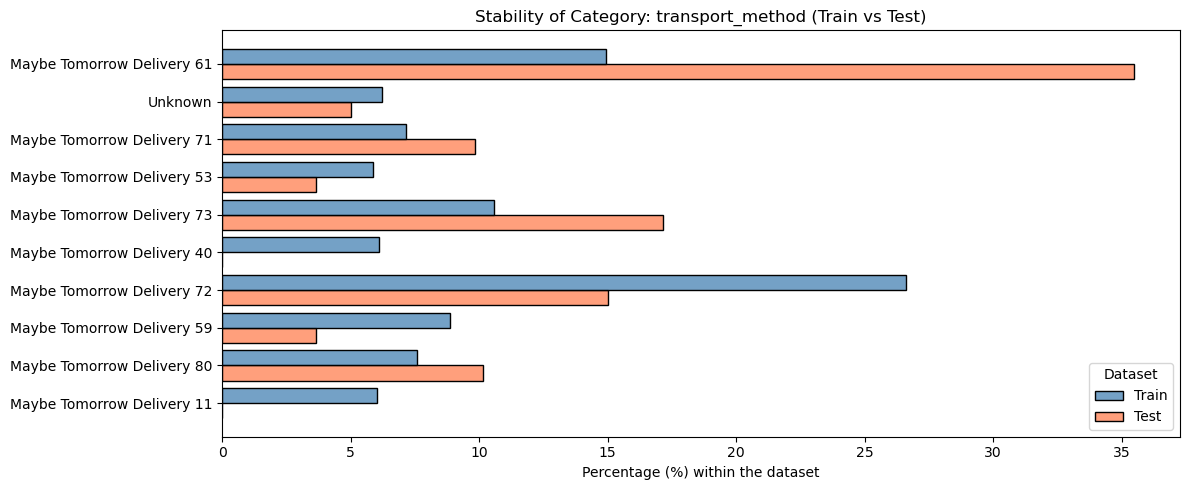

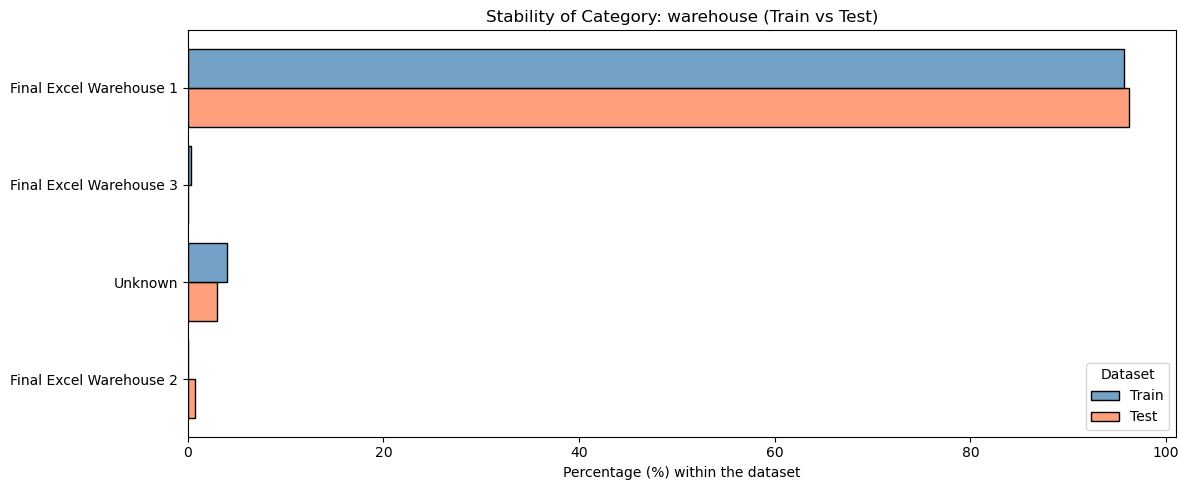

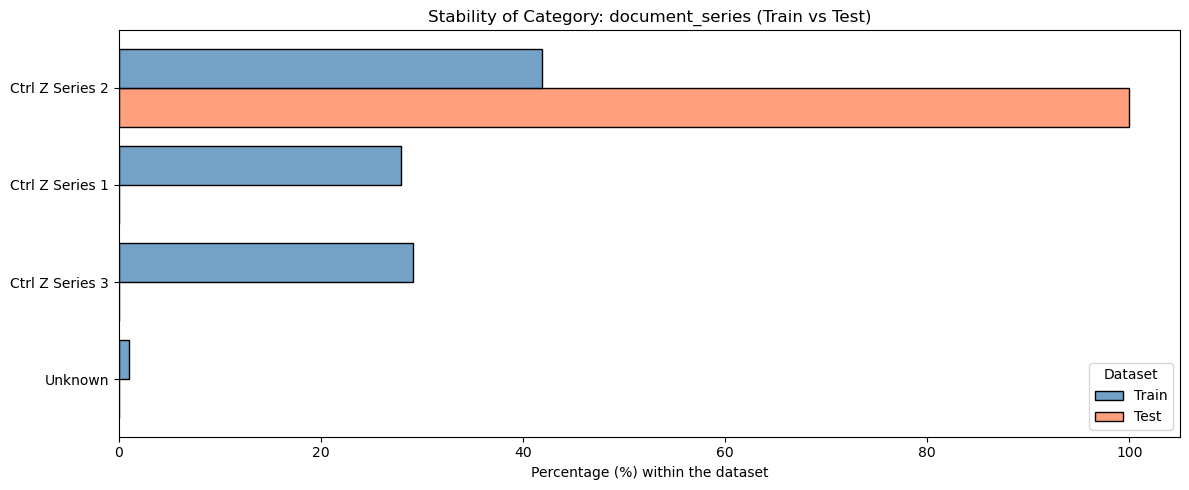

In [6]:
for col in cat_cols_test:
    tmp_train = pd.DataFrame({col: train[col].fillna('Unknown'), 'Dataset': 'Train'})
    if col in test.columns:
        tmp_test = pd.DataFrame({col: test[col].fillna('Unknown'), 'Dataset': 'Test'})
    else:
        tmp_test = pd.DataFrame(columns=[col, 'Dataset'])
        
    tmp_combined = pd.concat([tmp_train, tmp_test])
    unique_num = tmp_combined[col].nunique()
    plt.figure(figsize=(12, 5))
    
    if unique_num > 15:
        print(f"\nThe variable '{col}' has {unique_num} unique categories. Displaying only the Top 10.")
        ordem = tmp_train[col].value_counts().head(10).index
        dados_grafico = tmp_combined[tmp_combined[col].isin(ordem)]
    else:
        ordem = tmp_train[col].value_counts().index
        dados_grafico = tmp_combined
        
    sns.histplot(
        data=dados_grafico, y=col, hue='Dataset', multiple='dodge', 
        stat='percent', shrink=0.8, common_norm=False,
        palette={'Train': 'steelblue', 'Test': 'coral'}
    )
    
    plt.title(f'Stability of Category: {col} (Train vs Test)')
    plt.xlabel('Percentage (%) within the dataset')
    plt.ylabel('')
    plt.tight_layout()
    plt.show()

Comparing categorical distributions across the training and test sets reveals substantial **distributional shifts**. 

- **Major Shifts and Unseen Categories**
  - `document_series`: Training data is distributed across Series 2 (~42%), Series 1 (~28%), and Series 3 (~29%), whereas the test set contains only "Ctrl Z Series 2". This lack of variation limits the feature's usefulness in test predictions.
  - `commercial_zone`: Zone 4 decreases from ~96% in training to ~70% in testing, while Zone 1 accounts for nearly 20% of the test set but is absent from training. This creates a risk for encoders that cannot handle unseen categories.
  - `warehouse`: Warehouse 1 remains dominant (>95%), but Warehouse 2 appears only in the test set.

- **Major Changes in Category Proportions**
  - `salesperson`: "VLOOKUP Master 1" decreases from ~62% to ~48%, while "VLOOKUP Master 9" increases from ~5% to nearly 20%.
  - `transport_method`: "Delivery 61" rises from ~15% to over 35%, while "Delivery 40" disappears from the test set.

- **Most Stable Feature**
  - `payment_type`: Payment 7 and Payment 12 maintain similar proportions across both datasets, indicating greater distributional stability.


### Historical Variables Analysis

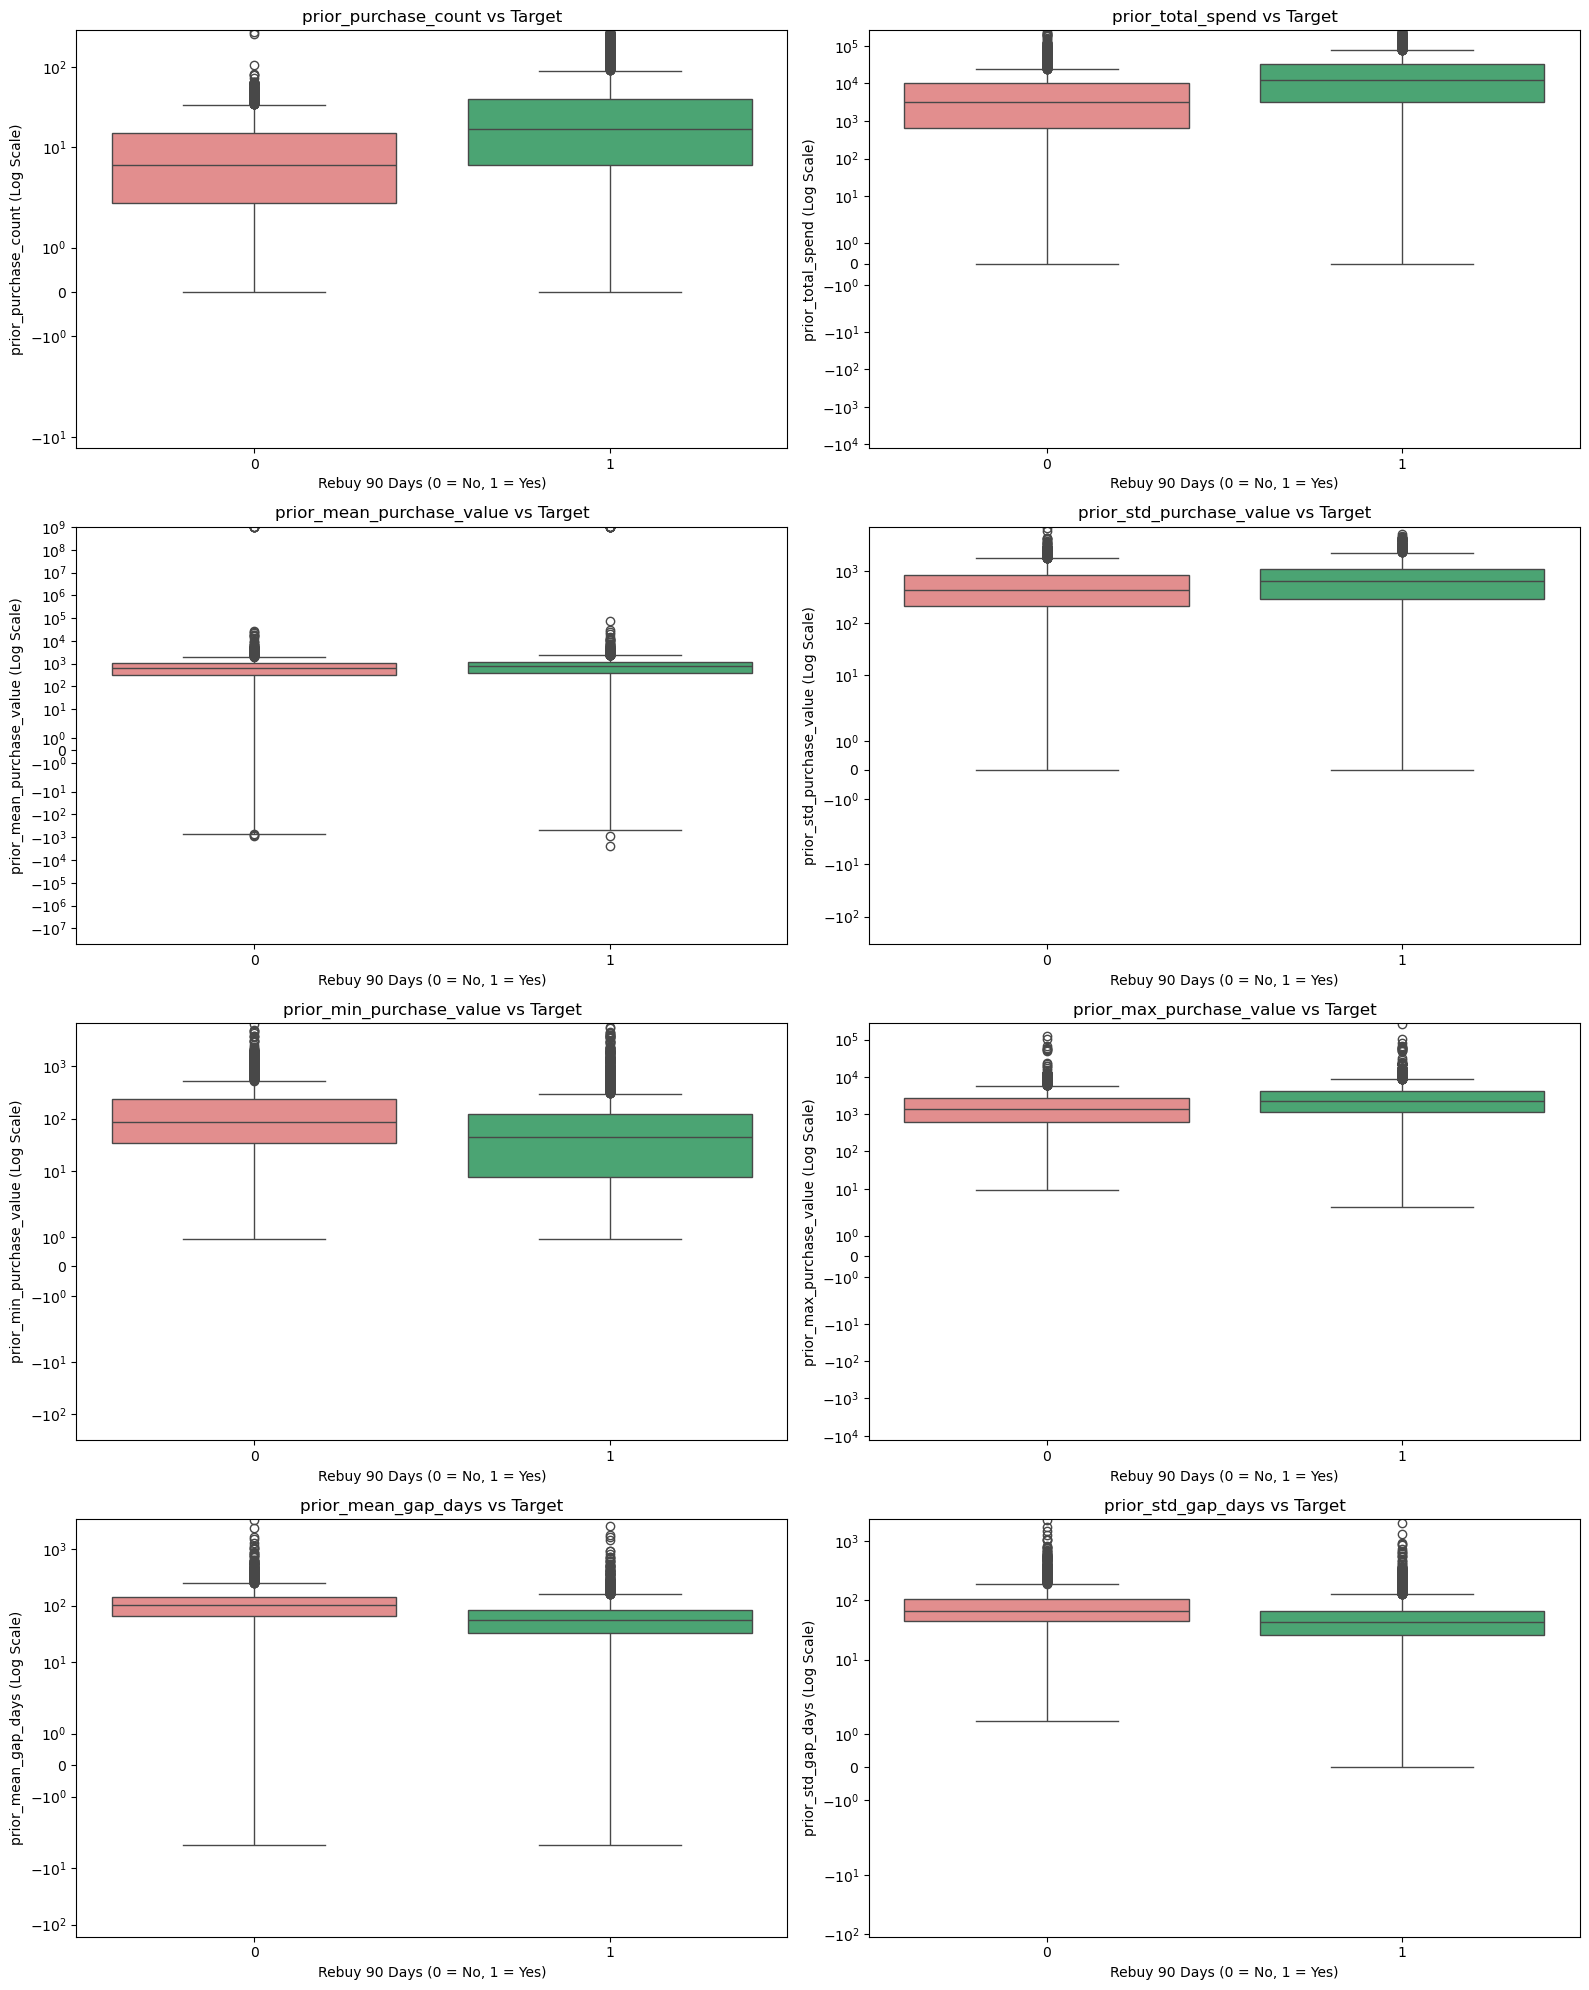

In [7]:
hist_cols = [
    'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 
    'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 
    'prior_mean_gap_days', 'prior_std_gap_days'
]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(hist_cols):
    sns.boxplot(
        data=train, 
        x='repeat_purchase_90d', 
        y=col, 
        ax=axes[i], 
        hue='repeat_purchase_90d', 
        palette={0: "lightcoral", 1: "mediumseagreen", "0": "lightcoral", "1": "mediumseagreen"}, 
        legend=False 
    )
    
    axes[i].set_title(f'{col} vs Target')
    axes[i].set_yscale('symlog') 
    axes[i].set_xlabel('Rebuy 90 Days (0 = No, 1 = Yes)')
    axes[i].set_ylabel(f'{col} (Log Scale)')

plt.tight_layout()
plt.show()

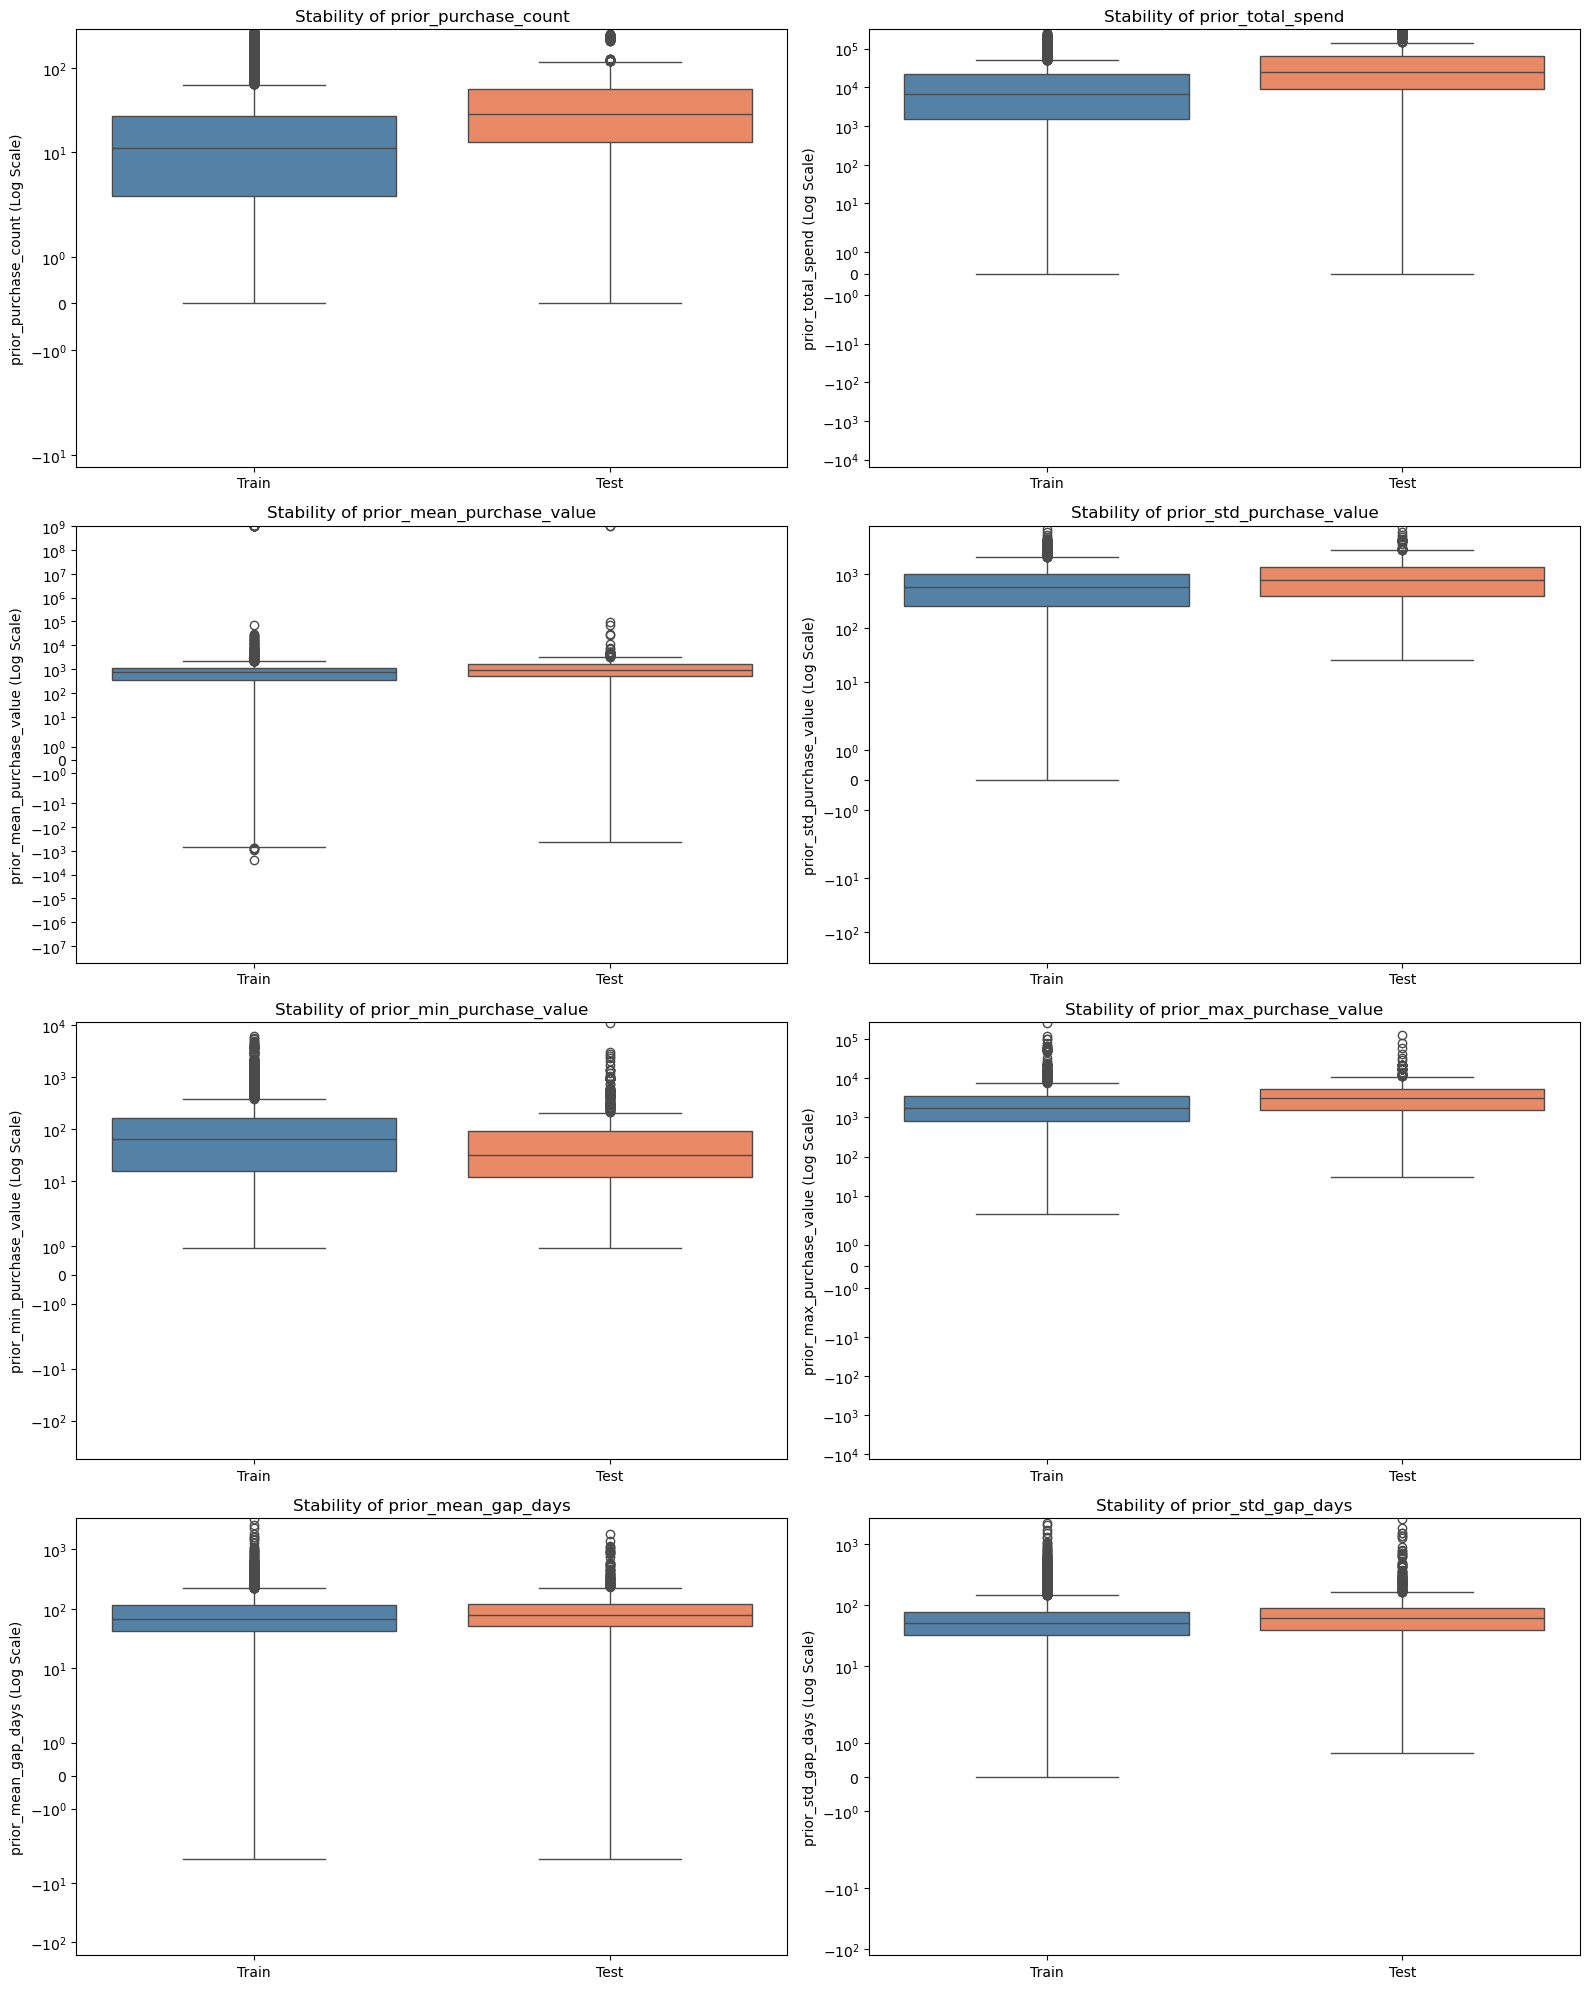

,Mean Train,Mean Test,Difference (%)
prior_purchase_count,2.345788e+01,4.290872e+01,82.92
prior_total_spend,1.890835e+04,4.943158e+04,161.43
prior_mean_purchase_value,2.821825e+06,2.142772e+06,-24.06
prior_std_purchase_value,7.374697e+02,1.032082e+03,39.95
prior_min_purchase_value,1.854620e+02,1.281855e+02,-30.88
prior_max_purchase_value,2.946378e+03,4.609242e+03,56.44
prior_mean_gap_days,9.587666e+01,1.107970e+02,15.56
prior_std_gap_days,7.413544e+01,9.803693e+01,32.24


In [ ]:
tmp_train = train[hist_cols].copy().reset_index(drop=True)
tmp_train['Dataset'] = 'Train'

tmp_test = test[hist_cols].copy().reset_index(drop=True)
tmp_test['Dataset'] = 'Test'

combined_hist = pd.concat([tmp_train, tmp_test], ignore_index=True)

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(hist_cols):
    sns.boxplot(
        data=combined_hist, 
        x='Dataset', 
        y=col, 
        ax=axes[i], 
        hue='Dataset', 
        palette={'Train': 'steelblue', 'Test': 'coral'},
        legend=False
    )
    axes[i].set_title(f'Stability of {col}')
    axes[i].set_yscale('symlog') 
    axes[i].set_ylabel(f'{col} (Log Scale)')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

mean_summary = pd.DataFrame({
    'Mean Train': train[hist_cols].mean(),
    'Mean Test': test[hist_cols].mean()
})
mean_summary['Difference (%)'] = ((mean_summary['Mean Test'] - mean_summary['Mean Train']) / mean_summary['Mean Train'] * 100).round(2)

display(mean_summary)

Historical behavioral features show strong predictive potential but also reveal substantial **distributional shifts (potential covariate shift)** between the training and test sets.

**1. Predictive Power (Relationship with the Target)**

Purchase frequency and cumulative spending appear to be key indicators of repeat purchasing.

- **Strong Differentiation:** Customers who repurchase (Target 1) have higher medians and distributions for `prior_purchase_count` and `prior_total_spend` than non-returning customers (Target 0).
- **Temporal Behavior:** `prior_mean_gap_days` has a slightly lower median for repeat purchasers, consistent with shorter intervals between invoices indicating more frequent activity.
- **Limited Differentiation:** Financial metrics such as `prior_mean_purchase_value` and `prior_min_purchase_value` show substantial overlap between the two target classes, suggesting limited standalone predictive power.

**2. Data Drift Alert (Train vs. Test)**

The test set contains customers with substantially higher historical activity and spending than the training set. This distributional shift may affect model generalization, as patterns learned from the training data may not transfer reliably to the test population.

- **Sharp Increase in Total Spending:** Mean `prior_total_spend` rises from approximately 18,908 in training to over 49,431 in testing (**+161.43%**).
- **Higher Purchase Frequency:** Mean `prior_purchase_count` increases from approximately 23.5 to 42.9 invoices (**+82.92%**).
- **Longer Intervals and Larger Peaks:** Mean `prior_max_purchase_value` increases by **56.44%**, while `prior_mean_gap_days` and `prior_std_gap_days` rise by **15.56%** and **32.24%**, respectively.
- **Lower Average and Minimum Purchase Values:** Mean `prior_mean_purchase_value` decreases by **24.06%**, while mean `prior_min_purchase_value` falls by **30.88%**.

These shifts suggest that the test set differs substantially in customer behavior, combining higher cumulative spending and purchase frequency with lower average and minimum transaction values. Further investigation is needed to determine whether this reflects a temporal effect, a change in customer composition, or differences in data preparation.

### Rolling Frequency Analysis

In [37]:
rolling_cols = [
    "purchase_count_30d",
    "purchase_count_90d",
    "purchase_count_180d",
    "purchase_count_365d"
]

# Compare the distributions by target class
summary = train.groupby("repeat_purchase_90d")[rolling_cols].agg(
    ["median", "mean"]
).T

display(summary)

repeat_purchase_90d                0         1
purchase_count_30d  median  0.000000  0.000000
                    mean    0.239817  0.884286
purchase_count_90d  median  0.000000  1.000000
                    mean    0.530899  2.497929
purchase_count_180d median  1.000000  3.000000
                    mean    1.317065  4.992820
purchase_count_365d median  2.000000  5.000000
                    mean    2.599368  9.677990

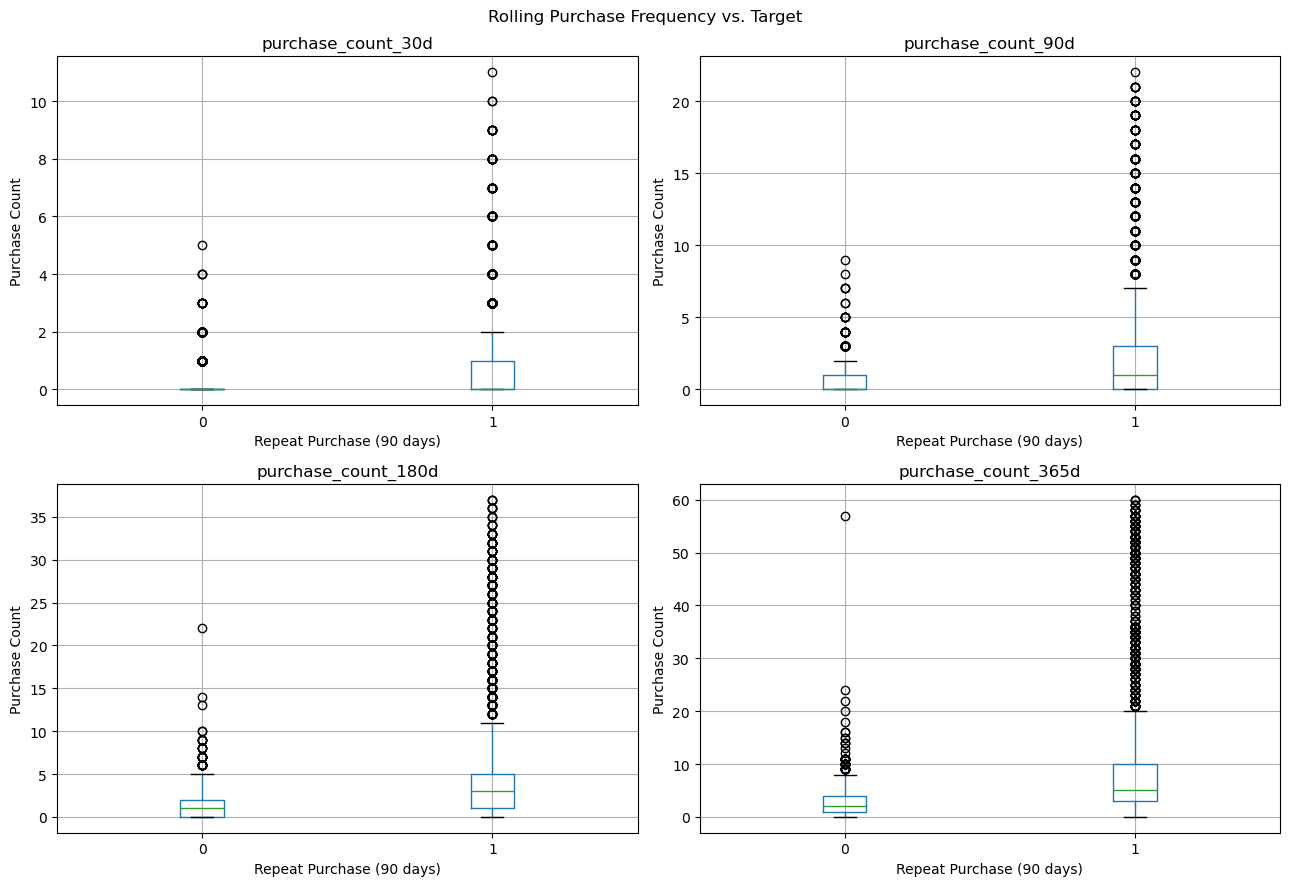

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, ax in zip(rolling_cols, axes.flatten()):
    train.boxplot(
        column=col,
        by="repeat_purchase_90d",
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("Repeat Purchase (90 days)")
    ax.set_ylabel("Purchase Count")
    
plt.suptitle("Rolling Purchase Frequency vs. Target")
plt.tight_layout()
plt.show()


In [ ]:
stability = pd.DataFrame({
    "Train_Median": train[rolling_cols].median(),
    "Test_Median": test[rolling_cols].median(),
    "Train_Mean": train[rolling_cols].mean(),
    "Test_Mean": test[rolling_cols].mean(),
    "Train_Missing_%": train[rolling_cols].isna().mean() * 100,
    "Test_Missing_%": test[rolling_cols].isna().mean() * 100
})

stability["Median_Change_%"] = (
    (stability["Test_Median"] - stability["Train_Median"])
    / stability["Train_Median"].replace(0, float("nan"))
    * 100
)

display(stability.round(2))

,Train_Median,Test_Median,Train_Mean,Test_Mean,Train_Missing_%,Test_Missing_%,Median_Change_%
purchase_count_30d,0.0,0.0,0.60,0.47,0.99,0.0,NaN
purchase_count_90d,1.0,1.0,1.63,1.40,0.99,0.0,0.00
purchase_count_180d,2.0,2.0,3.37,3.02,0.99,0.0,0.00
purchase_count_365d,3.0,4.0,6.56,6.51,0.99,0.0,33.33


In [ ]:
for name, df in [("Train", train), ("Test", test)]:
    print(f"\n--- {name} ---")

    for col in rolling_cols:
        active_pct = df[col].gt(0).mean() * 100
        print(f"{col}: {active_pct:.2f}% with at least one purchase")


--- Train ---
purchase_count_30d: 32.55% with at least one purchase
purchase_count_90d: 54.79% with at least one purchase
purchase_count_180d: 77.43% with at least one purchase
purchase_count_365d: 86.10% with at least one purchase

--- Test ---
purchase_count_30d: 32.35% with at least one purchase
purchase_count_90d: 59.23% with at least one purchase
purchase_count_180d: 83.47% with at least one purchase
purchase_count_365d: 94.02% with at least one purchase


**1. Predictive Power**

Historical purchase frequency differs substantially between customers who repurchase (`repeat_purchase_90d = 1`) and those who do not (`0`).

- **Short-term activity:** `purchase_count_30d` has a median of zero for both classes, although the mean is higher among repeat purchasers (0.88 vs. 0.24).
- **Medium-term activity:** Differences become more pronounced over 90 and 180 days. Median purchase counts increase from 0 to 1 and from 1 to 3, respectively, for non-repeat and repeat purchasers.
- **Long-term activity:** `purchase_count_365d` shows the largest absolute difference, with median counts of 2 and 5 and mean counts of 2.60 and 9.68, respectively.

Overall, repeat purchasers exhibit higher historical purchase frequency across all time windows, suggesting that rolling frequency features may provide useful predictive information. However, these descriptive differences do not establish which window performs best in a predictive model.

**2. Train–Test Stability**

The rolling frequency features show relatively stable means and medians across the training and test sets, although differences emerge in the proportion of customers with at least one purchase.

- **30 days:** The proportion of active customers is nearly identical (32.55% vs. 32.35%).
- **90 days:** The test set has a higher proportion of active customers (59.23% vs. 54.79%), despite a lower mean purchase count.
- **180 days:** The proportion increases from 77.43% to 83.47%, while the mean decreases from 3.37 to 3.02.
- **365 days:** The test set has a higher proportion of active customers (94.02% vs. 86.10%), and the median increases from 3 to 4 purchases, although the mean remains nearly unchanged.

These results suggest potential distributional differences, particularly in the longer observation windows. However, further distributional analysis is needed to determine their extent and significance. The higher proportion of active customers alongside lower or stable means may indicate differences in the distribution of purchase counts rather than a uniform increase in purchasing activity.

**3. Implications**

Rolling frequency features appear promising for predicting repeat purchases. Their incremental value should be assessed through cross-validation, comparing models with and without these features. Missing values should also be investigated to distinguish unavailable historical information from genuine zero purchase counts.

### Rolling Spend Analysis

In [ ]:
rolling_spend_cols = [
    "spend_30d",
    "spend_90d",
    "spend_180d",
    "spend_365d"
]

spend_summary = train.groupby("repeat_purchase_90d")[
    rolling_spend_cols
].agg(["median", "mean"]).T

display(spend_summary)

repeat_purchase_90d             0             1
spend_30d  median    0.000000e+00  0.000000e+00
           mean      2.352870e+02  6.316343e+02
spend_90d  median    0.000000e+00  7.461900e+02
           mean      5.417338e+02  1.813371e+03
spend_180d median    4.578700e+02  2.106220e+03
           mean      1.286172e+03  3.723753e+03
spend_365d median    1.138940e+03  4.552940e+03
           mean      1.812451e+06  2.856183e+06

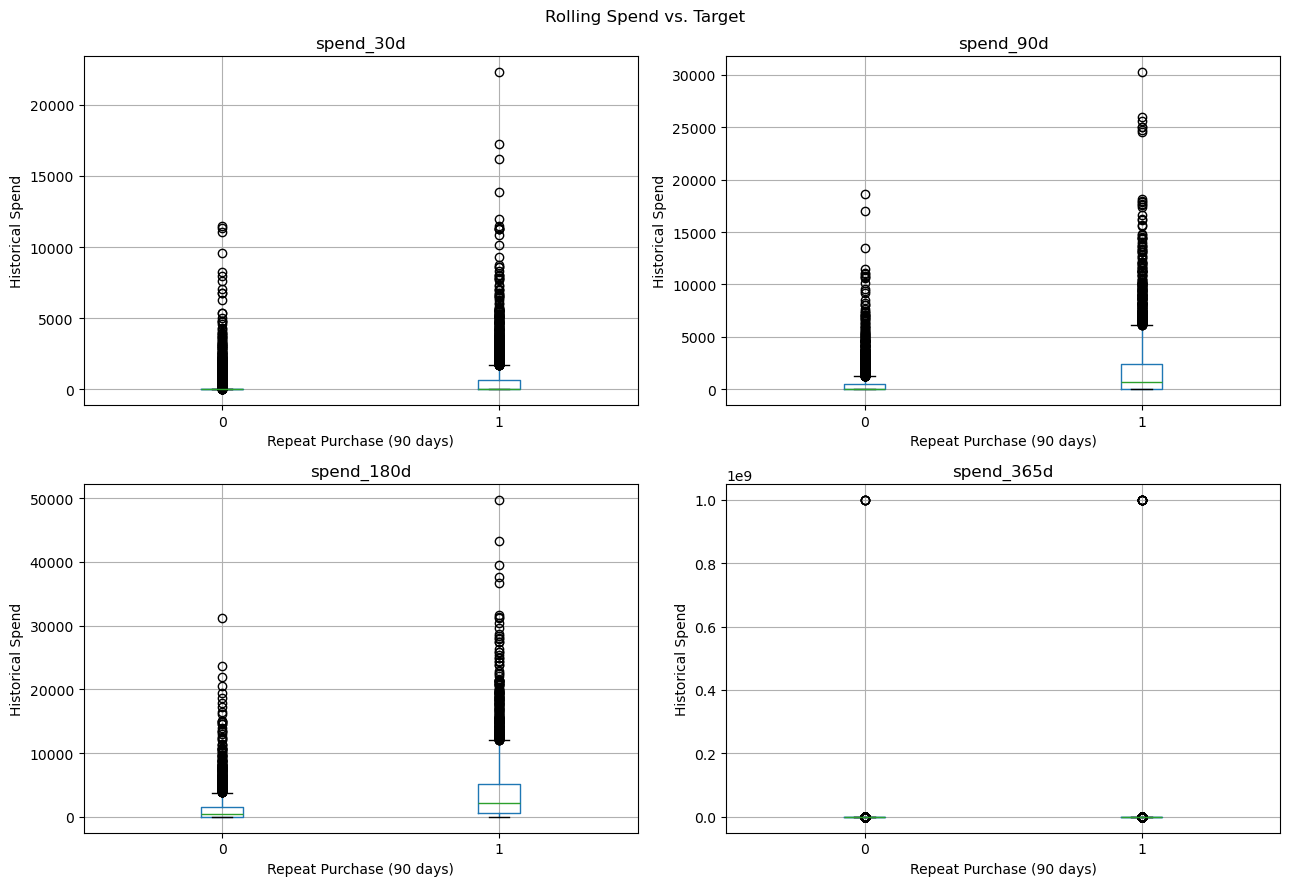

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, ax in zip(rolling_spend_cols, axes.flatten()):
    train.boxplot(
        column=col,
        by="repeat_purchase_90d",
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("Repeat Purchase (90 days)")
    ax.set_ylabel("Historical Spend")

plt.suptitle("Rolling Spend vs. Target")
plt.tight_layout()
plt.show()

In [ ]:

spend_stability = pd.DataFrame({
    "Train_Median": train[rolling_spend_cols].median(),
    "Test_Median": test[rolling_spend_cols].median(),
    "Train_Mean": train[rolling_spend_cols].mean(),
    "Test_Mean": test[rolling_spend_cols].mean(),
    "Train_Missing_%": train[rolling_spend_cols].isna().mean() * 100,
    "Test_Missing_%": test[rolling_spend_cols].isna().mean() * 100
})

spend_stability["Median_Change_Absolute"] = (
    spend_stability["Test_Median"]
    - spend_stability["Train_Median"]
)

spend_stability["Median_Change_%"] = (
    spend_stability["Median_Change_Absolute"]
    / spend_stability["Train_Median"].replace(0, float("nan"))
    * 100
)

display(spend_stability.round(2))

,Train_Median,Test_Median,Train_Mean,Test_Mean,Train_Missing_%,Test_Missing_%,Median_Change_Absolute,Median_Change_%
spend_30d,0.00,0.00,457.14,641.81,0.99,0.00,0.00,NaN
spend_90d,198.50,472.72,1253.53,1730.72,0.99,0.00,274.22,138.15
spend_180d,1117.68,2168.00,2650.60,3879.46,0.99,0.00,1050.32,93.97
spend_365d,2426.60,5423.65,2396534.88,2100944.27,3.98,3.04,2997.04,123.51


In [ ]:

for name, df in [("Train", train), ("Test", test)]:
    print(f"\n--- {name} ---")

    for col in rolling_spend_cols:
        positive_pct = df[col].gt(0).mean() * 100
        zero_pct = df[col].eq(0).mean() * 100
        missing_pct = df[col].isna().mean() * 100

        print(
            f"{col}: positive={positive_pct:.2f}%, "
            f"zero={zero_pct:.2f}%, "
            f"missing={missing_pct:.2f}%"
        )



--- Train ---
spend_30d: positive=32.55%, zero=66.45%, missing=0.99%
spend_90d: positive=54.79%, zero=44.21%, missing=0.99%
spend_180d: positive=77.43%, zero=21.58%, missing=0.99%
spend_365d: positive=83.39%, zero=12.40%, missing=3.98%

--- Test ---
spend_30d: positive=32.35%, zero=67.65%, missing=0.00%
spend_90d: positive=59.23%, zero=40.77%, missing=0.00%
spend_180d: positive=83.47%, zero=16.53%, missing=0.00%
spend_365d: positive=90.87%, zero=5.88%, missing=3.04%


#### Analysis spend_365d

In [ ]:

for name, df in [("Train", train), ("Test", test)]:
    s = df["spend_365d"]

    print(f"\n--- {name}: spend_365d ---")
    print("Min:", s.min())
    print("Max:", s.max())
    print("Mean:", s.mean())
    print("Median:", s.median())
    print("Negative values:", (s < 0).sum())
    print("Zero values:", (s == 0).sum())
    print("Missing values:", s.isna().sum())
    print("\nQuantiles:")
    print(s.quantile([0.01, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]))



--- Train: spend_365d ---
Min: -159115.17553487257
Max: 1000000000.0
Mean: 2396534.8758331565
Median: 2426.605
Negative values: 15
Zero values: 810
Missing values: 260

Quantiles:
0.010    0.000000e+00
0.250    6.377825e+02
0.500    2.426605e+03
0.750    7.045423e+03
0.950    2.222760e+04
0.990    4.087680e+04
0.999    1.000000e+09
Name: spend_365d, dtype: float64

--- Test: spend_365d ---
Min: -3856.64
Max: 1000000000.0
Mean: 2100944.268298501
Median: 5423.65
Negative values: 2
Zero values: 58
Missing values: 30

Quantiles:
0.010    0.000000e+00
0.250    1.689405e+03
0.500    5.423650e+03
0.750    1.072359e+04
0.950    3.013416e+04
0.990    5.604160e+04
0.999    1.000000e+09
Name: spend_365d, dtype: float64


In [ ]:
for name, df in [("Train", train), ("Test", test)]:
    print(f"\n--- {name} ---")

    print(
        "Values equal to 1 billion:",
        (df["spend_365d"] == 1_000_000_000).sum()
    )

    # Inspecionar as observações afetadas
    suspicious = df[df["spend_365d"] == 1_000_000_000]

    print(suspicious[
        [
            "spend_30d",
            "spend_90d",
            "spend_180d",
            "spend_365d",
            "prior_total_spend",
            "prior_mean_purchase_value",
            "prior_max_purchase_value"
        ]
    ])


--- Train ---
Values equal to 1 billion: 15
      spend_30d  spend_90d  spend_180d    spend_365d  prior_total_spend  \
916      214.91     239.24      818.02  1.000000e+09            8467.22   
1029       0.00    2411.42    15709.98  1.000000e+09          102909.17   
1630       0.00       0.00        0.00  1.000000e+09               0.00   
1941       0.00       0.00     2150.66  1.000000e+09           51288.79   
2356       0.00       0.00     1097.89  1.000000e+09            1741.18   
2369    2038.75    2038.75     4832.85  1.000000e+09          118404.68   
2590    2165.94    3320.99     5839.88  1.000000e+09           28185.61   
3324       0.00     234.24      652.67  1.000000e+09            7119.32   
3514       0.00       0.00       51.62  1.000000e+09            1847.78   
4155       0.00       0.00     3386.26  1.000000e+09           63397.28   
4395       0.00       0.00      977.42  1.000000e+09             977.42   
4607       0.00     391.12     1643.29  1.000000e+09   


Historical spending is higher among customers who repurchase (`repeat_purchase_90d = 1`). For example, the median `spend_90d` increases from `0.00` to `746.19`, while `spend_180d` rises from `457.87` to `2,106.22`. These differences suggest that rolling spend features may provide useful predictive information.

The value `1,000,000,000.0` occurs in 15 training and 2 test observations, drastically inflating the mean. This is a suspected sentinel value or data error that requires investigation. Negative values were also identified (15 in training and 2 in testing) and should be checked to determine whether they represent legitimate returns or errors.

Zero values are more common in shorter spending windows: `spend_30d` has approximately 66–68% zeros, compared with 6–12% for `spend_365d`. Missing values are more frequent in the annual spending feature (3.98% in training and 3.04% in testing). Missing values should not automatically be replaced with zero unless they represent no spending.

Median spending is higher in the test set across the 90-, 180-, and 365-day windows, suggesting a potential distribution shift that may affect model generalisation.

### Random Noise Analysis


Analysing random_noise


,random_noise
count,6469.000000
mean,-0.022140
std,1.001054
min,-3.529210
25%,-0.677770
50%,-0.045714
75%,0.641711
max,4.151241


Unique values: 6469


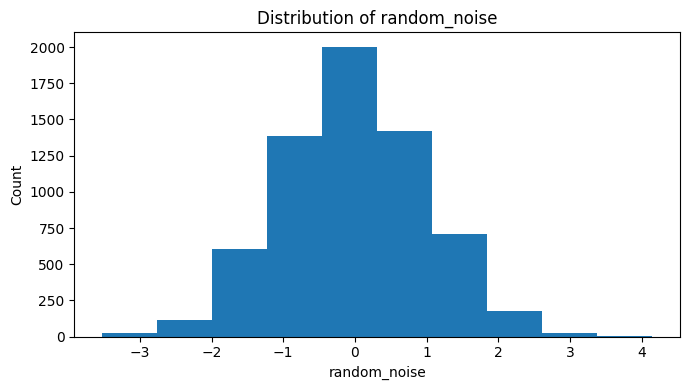

In [ ]:
for col in other_features:

    print(f"\nAnalysing {col}")
    display(train[col].describe().to_frame())

    print("Unique values:", train[col].nunique(dropna=True))

    plt.figure(figsize=(7, 4))
    plt.hist(train[col].dropna())
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

if not other_features:
    print("No random_noise column was found.")

- Distribution: random_noise is approximately centred around zero, with a mean of -0.02 and a median of -0.05.

- Variability: The standard deviation is approximately 1.00, consistent with a standard normal-like distribution.

- Range: Values range from -3.53 to 4.15, with no immediately obvious extreme values based on the summary statistics.

## Target Exploration

### Classification Target Analysis - repeat_purchase_90d

Target value counts:


,count
repeat_purchase_90d,
0,2880
1,3654


Target proportions:


,percentage
repeat_purchase_90d,
0,44.08
1,55.92


Missing target values: 0
Invalid target values: 0


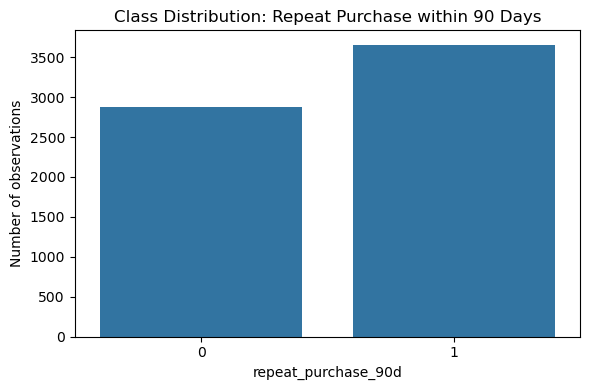

In [ ]:
target_cls = "repeat_purchase_90d"

if target_cls in train.columns:

    print("Target value counts:")
    display(
        train[target_cls]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("count")
    )

    print("Target proportions:")
    display(
        (
            train[target_cls]
            .value_counts(normalize=True, dropna=False)
            * 100
        )
        .sort_index()
        .to_frame("percentage")
        .round(2)
    )

    print("Missing target values:", train[target_cls].isna().sum())

    valid_labels = {0, 1}

    invalid_mask = (
        train[target_cls].notna()
        & ~train[target_cls].isin(valid_labels)
    )

    print("Invalid target values:", invalid_mask.sum())

    plt.figure(figsize=(6, 4))

    sns.countplot(
        data=train,
        x=target_cls,
        order=sorted(train[target_cls].dropna().unique())
    )

    plt.title("Class Distribution: Repeat Purchase within 90 Days")
    plt.xlabel("repeat_purchase_90d")
    plt.ylabel("Number of observations")
    plt.tight_layout()
    plt.show()

    class_proportions = train[target_cls].value_counts(normalize=True)

else:
    print(f"{target_cls} not found.")

The target is relatively balanced, with a slight majority of class 1. 

### Regression Target Analysis - spend_next_90d

Target summary:


count     3425.00
mean      1921.53
std       2571.05
min          1.27
25%        318.48
50%        985.74
75%       2464.56
max      25654.33
Name: spend_next_90d, dtype: float64

Missing values: 3109
Zero values: 0
Negative values: 0


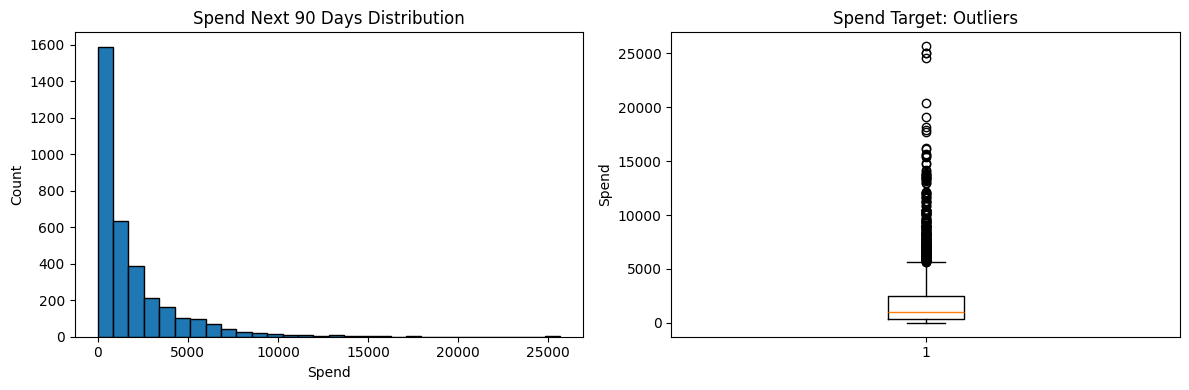

In [ ]:
target_reg = "spend_next_90d"

if target_reg in train.columns:

    y = train[target_reg].dropna()

    print("Target summary:")
    display(y.describe().round(2))

    print("Missing values:", train[target_reg].isna().sum())
    print("Zero values:", (y == 0).sum())
    print("Negative values:", (y < 0).sum())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(y, bins=30, edgecolor="black")
    axes[0].set_title("Spend Next 90 Days Distribution")
    axes[0].set_xlabel("Spend")
    axes[0].set_ylabel("Count")

    axes[1].boxplot(y)
    axes[1].set_title("Spend Target: Outliers")
    axes[1].set_ylabel("Spend")

    plt.tight_layout()
    plt.show()

else:
    print(f"{target_reg} not found.")

- Missing values: 3,109 values (47.58%) are missing, leaving 3,425 observations for regression modelling.

- Distribution: Spending is likely right-skewed. 

- Extreme values: The maximum (25,654.33) is much higher than the median, suggesting potential outliers.

We must investigate the missing target values and consider a log transformation to reduce skewness. 

In [ ]:
target = "spend_next_90d"

missing = train[train[target].isna()]
available = train[train[target].notna()]

print("Missing target:", len(missing))
print("Available target:", len(available))
print("Missing percentage:", round(train[target].isna().mean() * 100, 2), "%")

print("\nRepeat purchase rate:")
display(
    train.groupby(train[target].isna())["repeat_purchase_90d"]
    .mean()
    .mul(100)
    .rename(index={True: "Spend missing", False: "Spend available"})
    .to_frame("Repeat purchase (%)")
    .round(2)
)

features = [
    "Total a Pagar",
    "prior_total_spend",
    "prior_purchase_count",
    "purchase_count_90d",
    "spend_90d"
]

print("\nFeature averages:")
display(
    train.groupby(train[target].isna())[features]
    .mean()
    .rename(index={True: "Spend missing", False: "Spend available"})
    .round(2)
)

train["purchase_date"] = pd.to_datetime(train["purchase_date"], errors="coerce")

print("\nPurchase date range:")
display(
    train.groupby(train[target].isna())["purchase_date"]
    .agg(["min", "max"])
    .rename(index={True: "Spend missing", False: "Spend available"})
)

Missing target: 3109
Available target: 3425
Missing percentage: 47.58 %

Repeat purchase rate:


,Repeat purchase (%)
spend_next_90d,
Spend available,100.00
Spend missing,7.37



Feature averages:


,Total a Pagar,prior_total_spend,prior_purchase_count,purchase_count_90d,spend_90d
spend_next_90d,,,,,
Spend available,1015.44,25796.91,33.40,2.55,1805.74
Spend missing,824.42,11157.58,12.27,0.60,632.19



Purchase date range:


,min,max
spend_next_90d,,
Spend available,2015-07-12,2025-02-15
Spend missing,2015-07-11,2025-02-15


- Repeat purchase: Only 7.37% of rows with missing spending have a repeat purchase, compared with 100% of rows with available spending. This suggests the missingness is strongly related to the classification target.

- Customer behaviour: Rows with missing spending have lower average prior spending, purchase frequency, recent purchase counts, and recent spending.

- Purchase dates: Both groups cover almost the same date range, so the missingness does not appear to be explained simply by the overall date range.

### Classification-Regression Target Consistency

## Relationships Between Variables

### Correlation Analysis

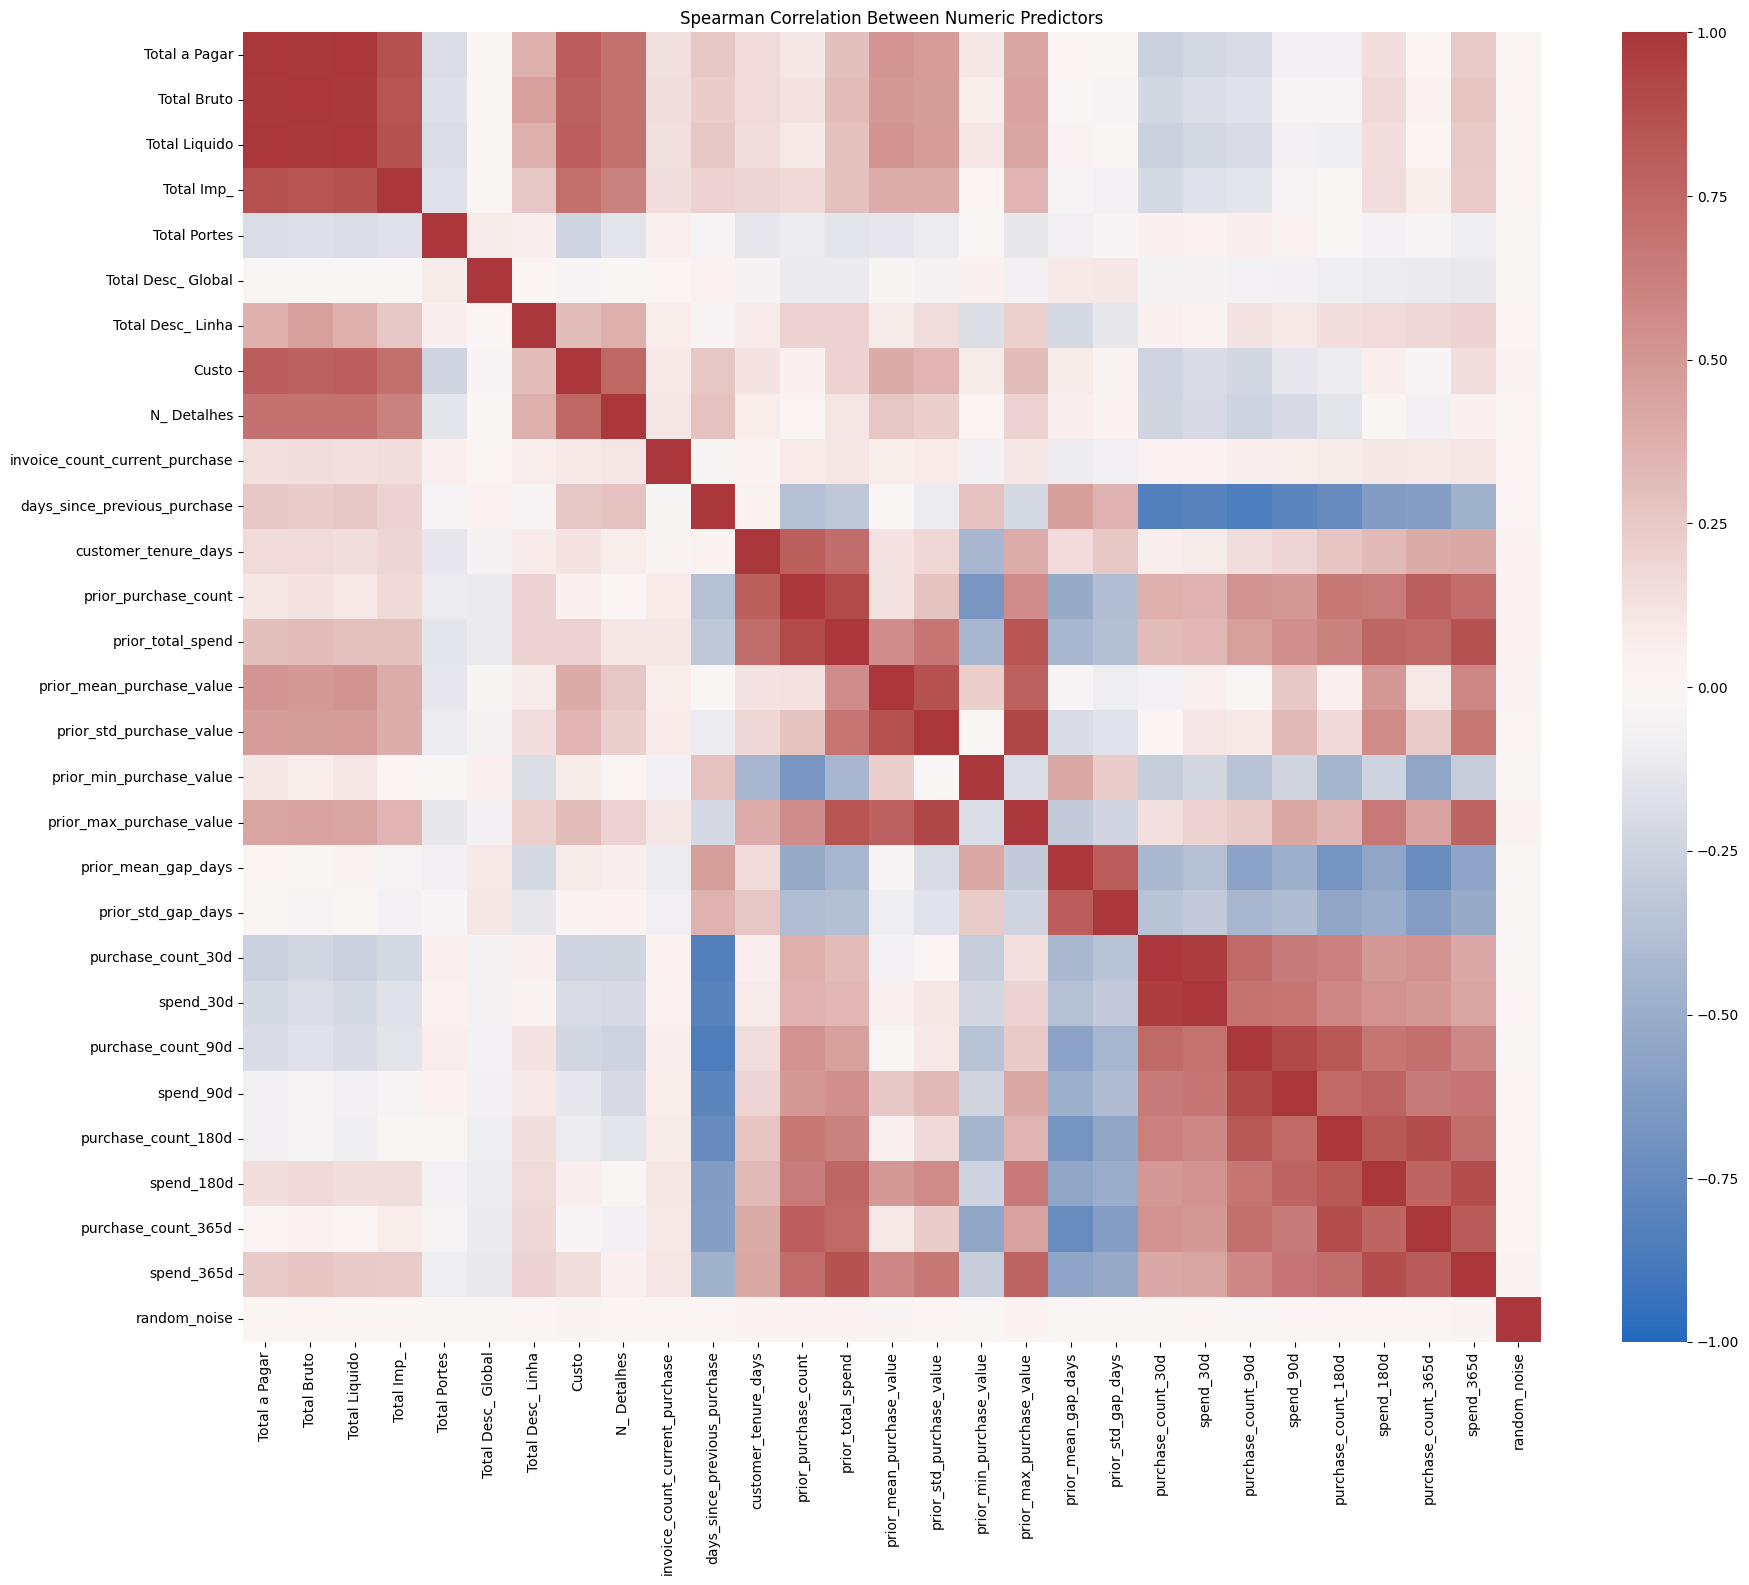

Highly correlated pairs: |correlation| >= 0.85


,,spearman_correlation,absolute_correlation
Total a Pagar,Total Liquido,0.999547,0.999547
Total Bruto,Total Liquido,0.991385,0.991385
Total a Pagar,Total Bruto,0.990854,0.990854
purchase_count_30d,spend_30d,0.965454,0.965454
prior_std_purchase_value,prior_max_purchase_value,0.922818,0.922818
purchase_count_90d,spend_90d,0.909204,0.909204
prior_purchase_count,prior_total_spend,0.903270,0.903270
purchase_count_180d,purchase_count_365d,0.888429,0.888429
spend_180d,spend_365d,0.888004,0.888004
prior_mean_purchase_value,prior_std_purchase_value,0.874926,0.874926


In [ ]:
numeric_predictors = train[predictor_cols].select_dtypes(
    include="number"
).columns.tolist()

if len(numeric_predictors) >= 2:

    correlation_matrix = train[numeric_predictors].corr(method="spearman")

    plt.figure(figsize=(
        max(10, len(numeric_predictors) * 0.65),
        max(8, len(numeric_predictors) * 0.55)
    ))

    sns.heatmap(
        correlation_matrix,
        cmap="vlag",
        center=0,
        vmin=-1,
        vmax=1
    )

    plt.title("Spearman Correlation Between Numeric Predictors")
    plt.tight_layout()
    plt.show()

    upper_triangle = correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )

    high_correlations = (
        upper_triangle.stack()
        .rename("spearman_correlation")
        .to_frame()
    )

    high_correlations["absolute_correlation"] = (
        high_correlations["spearman_correlation"].abs()
    )

    high_correlations = high_correlations[
        high_correlations["absolute_correlation"] >= 0.85
    ].sort_values("absolute_correlation", ascending=False)

    print("Highly correlated pairs: |correlation| >= 0.85")
    display(high_correlations)

else:
    print("Not enough numeric predictors for correlation analysis.")

- Strong correlations: Some variables contain similar information, especially Total a Pagar, Total Bruto, and Total Liquido.

- Purchase frequency and spending: Purchase counts and spending amounts are strongly correlated across different time windows.

- Historical features: Previous spending and purchase statistics also show strong correlations.

- Expected relationships: Overlapping time windows naturally produce correlated features.

- Purchase recency: More days since the previous purchase is associated with lower recent purchase frequency.

### Predictor-Target Relationships

Customers labeled 0 (No Rebuy) but with future spend > 0: 0 records
Customers labeled 1 (Rebuy) but with future spend <= 0: 0 records



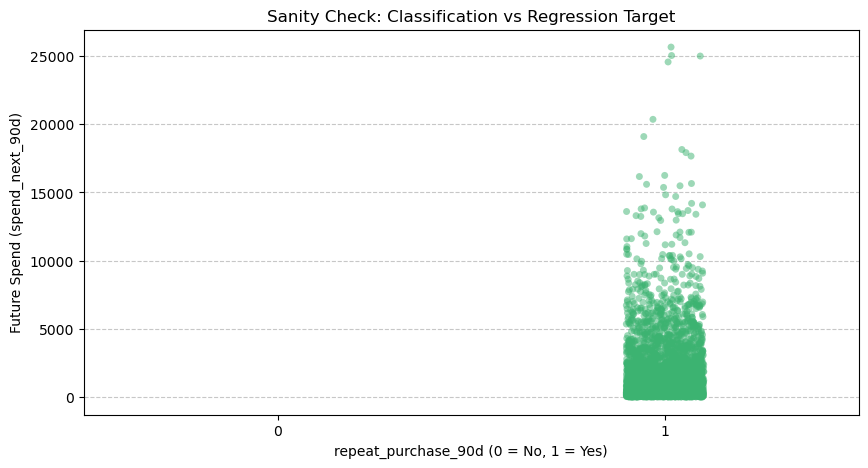


Classification and Regression targets are 100% consistent.


In [9]:

regression_target_col = 'spend_next_90d' 

if regression_target_col in train.columns:
    false_negative_error = train[(train['repeat_purchase_90d'] == 0) & (train[regression_target_col] > 0)]
    false_positive_error = train[(train['repeat_purchase_90d'] == 1) & (train[regression_target_col] <= 0)]
    
    print(f"Customers labeled 0 (No Rebuy) but with future spend > 0: {len(false_negative_error)} records")
    print(f"Customers labeled 1 (Rebuy) but with future spend <= 0: {len(false_positive_error)} records\n")
    
    plt.figure(figsize=(10, 5))
    sns.stripplot(
        data=train, 
        x='repeat_purchase_90d', 
        y=regression_target_col, 
        jitter=True, 
        alpha=0.5, 
        hue='repeat_purchase_90d',
        palette={0: "lightcoral", 1: "mediumseagreen"},
        legend=False
    )
    plt.title('Sanity Check: Classification vs Regression Target')
    plt.xlabel('repeat_purchase_90d (0 = No, 1 = Yes)')
    plt.ylabel(f'Future Spend ({regression_target_col})')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
    
    if len(false_negative_error) > 0 or len(false_positive_error) > 0:
        print("\n--- Sample of Inconsistent Records ---")
        inconsistent_records = pd.concat([false_negative_error, false_positive_error])
        display(inconsistent_records[['customer_id', 'repeat_purchase_90d', regression_target_col]].head(10))
    else:
        print("\nClassification and Regression targets are 100% consistent.")
else:
    print(f"Theres no column named '{regression_target_col}' in the train dataset.")

The cross-check between **repeat_purchase_90d** and **spend_next_90d** identified no contradictory records, suggesting consistency between the two targets. However, this does not independently rule out data leakage.

Missing values in **spend_next_90d** appear to represent customers with no future spending, rather than explicit zero values. This interpretation should be verified before preprocessing.

## Modelling Readiness

### Compare Train and Test Distributions

In [ ]:
shared_predictors = sorted(
    (set(train.columns) & set(test.columns))
    - {
        "ID",
        "customer_id",
        "purchase_date",
        "repeat_purchase_90d",
        "spend_next_90d"
    }
)

comparison = []

for col in shared_predictors:

    comparison.append({
        "feature": col,
        "train_dtype": str(train[col].dtype),
        "test_dtype": str(test[col].dtype),
        "train_missing_pct": train[col].isna().mean() * 100,
        "test_missing_pct": test[col].isna().mean() * 100,
        "train_unique": train[col].nunique(dropna=True),
        "test_unique": test[col].nunique(dropna=True)
    })

comparison = pd.DataFrame(comparison)

display(
    comparison.sort_values(
        "test_missing_pct",
        ascending=False
    ).round(2)
)

for col in shared_predictors:

    if (
        pd.api.types.is_object_dtype(train[col])
        or isinstance(train[col].dtype, pd.CategoricalDtype)
        or pd.api.types.is_object_dtype(test[col])
        or isinstance(test[col].dtype, pd.CategoricalDtype)
    ):

        train_categories = set(
            train[col].dropna().astype(str)
        )

        test_categories = set(
            test[col].dropna().astype(str)
        )

        unseen_categories = test_categories - train_categories

        if unseen_categories:

            print(
                f"{col}: {len(unseen_categories)} "
                "categories appear in test but not train."
            )

            print("Examples:", list(unseen_categories)[:10])

,feature,train_dtype,test_dtype,train_missing_pct,test_missing_pct,train_unique,test_unique
16,prior_mean_gap_days,float64,float64,20.02,7.71,3874,891
20,prior_std_gap_days,float64,float64,22.62,7.00,4911,917
17,prior_mean_purchase_value,float64,float64,13.19,5.27,5651,933
11,days_since_previous_purchase,float64,float64,13.18,5.27,495,256
21,prior_std_purchase_value,float64,float64,17.03,4.67,5420,939
28,salesperson,str,str,3.96,3.04,9,3
31,spend_365d,float64,float64,3.98,3.04,5434,898
33,transport_method,str,str,3.99,3.04,80,29
34,warehouse,str,str,3.98,3.04,2,2
14,payment_type,str,str,3.98,3.04,9,11


1. General consistency between train and test

- Most predictor variables are present in both datasets, allowing the same features to be used for model training and prediction.

- The majority of variables have similar data types across the two datasets.

- Some variables differ in data type, such as N_Detalhes, customer_tenure_days, and the purchase-count variables, which are stored as float64 in train and int64 in test. These differences are not necessarily problematic, but data types should be standardized where appropriate to ensure consistency during preprocessing.

2. Missing values

- The highest missing-value percentages occur in historical purchase behavior variables, particularly prior_mean_gap_days (20.02% in train) and prior_std_gap_days (22.62% in train).

- Historical purchase-value statistics, such as prior_mean_purchase_value and prior_std_purchase_value, also contain substantial missingness.

- These missing values may indicate customers with limited purchase histories or insufficient information to calculate historical statistics.

- Several variables, including salesperson, spend_365d, and transport_method, have approximately 3–4% missing values in train and test.
 
- Most remaining predictors have very low missingness, around 0.99% in train and none in test.

3. Differences in missingness between train and test

- Several historical features have considerably more missing values in train than in test. For example, prior_std_gap_days has 22.62% missingness in train compared with 7.00% in test.

- This difference may reflect differences in customer purchase histories or dataset composition.

- The same pattern appears in historical purchase-value statistics and days_since_previous_purchase.

4. Categorical variables and unseen categories

- Some categorical variables have different numbers of unique values across the datasets.

- For example, payment_type has 9 unique values in train and 11 in test, suggesting that test may contain payment categories not observed during training.

- Categorical variables should be checked for unseen test categories. The encoding strategy must handle categories that were not observed during training, particularly for payment_type and transport_method. The number of unique values alone does not establish whether unseen categories exist; the explicit category comparison determines that.

5. Differences in the number of unique values

- Most numerical predictors have substantially fewer unique values in test than in train, which is expected when the test dataset contains fewer observations.

- For example, Total Liquido has 6,093 unique values in train and 971 in test.

- Purchase-frequency and spending variables also show fewer unique values in test, reflecting the smaller range of observations available.

6. Potentially irrelevant or problematic features

- random_noise appears to have many unique numerical values but is explicitly named as a noise variable.

- If this variable was intentionally generated randomly, it is unlikely to provide meaningful predictive information and may encourage overfitting.

- Identifiers such as ID and customer_id, as well as purchase_date and the target variables, were excluded from the shared predictors in this comparison.

### Analyse clients.csv

In [ ]:
print("Clientes dimensions:", clientes.shape)
print("Columns:", clientes.columns.tolist())

display(clientes.head())

print(
        "Exact duplicate rows:",
        clientes.duplicated().sum()
    )

if "customer_id" not in clientes.columns:

    print("WARNING: customer_id was not found. Inspect the join key before proceeding.")

else:
        print("Missing customer IDs:", clientes["customer_id"].isna().sum())    

        print("Unique customer IDs:", clientes["customer_id"].nunique())        

        print("Duplicate customer IDs:", clientes["customer_id"].duplicated().sum())

        if "customer_id" in train.columns:

            train_customers = set(train["customer_id"].dropna())

            clientes_customers = set(clientes["customer_id"].dropna())

            print("Train customers absent from clientes:", len(train_customers - clientes_customers))

            print("Clientes customers absent from train:", len(clientes_customers - train_customers))

        if not clientes["customer_id"].duplicated().any():

            print("The clientes key is unique. A many-to-one left join can be considered.")

        else:

            print("Do not merge yet: investigate duplicate customer keys.")

Clientes dimensions: (1143, 13)
Columns: ['customer_id', 'country_or_region', 'commercial_region', 'island', 'municipality', 'city', 'postal_area', 'postal_code', 'street', 'address', 'customer_type', 'company_name', 'customer_since_year']


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


Exact duplicate rows: 0
Missing customer IDs: 0
Unique customer IDs: 1143
Duplicate customer IDs: 0
Train customers absent from clientes: 0
Clientes customers absent from train: 533
The clientes key is unique. A many-to-one left join can be considered.


- Customer identifiers: customer_id has no missing values or duplicates, making it a suitable key for merging.

- Customer coverage: All 610 customers in the training dataset are present in Clientes. The remaining 533 customers do not appear in the training data.

- Merge suitability: A left join from train or test to Clientes using customer_id is appropriate because the customer key is unique in Clientes.

- Data quality: Several geographic fields contain substantial missingness, customer_type is entirely missing, and postal_code contains apparent Excel reference errors. These columns require cleaning before use.

- Modelling considerations: Customer information may provide useful geographic or demographic context, but each feature should be assessed for data quality, predictive value, and availability at prediction time.

### Check Data Leakage Risks

In [ ]:
print("Leakage Checklist:")

print(
    "Classification target excluded from predictors:",
    "repeat_purchase_90d" not in predictor_cols
)

print(
    "Regression target excluded from predictors:",
    "spend_next_90d" not in predictor_cols
)

print(
    "ID excluded from default predictors:",
    "ID" not in predictor_cols
)

print(
    "customer_id excluded from default predictors:",
    "customer_id" not in predictor_cols
)

print(
    "purchase_date excluded from default predictors:",
    "purchase_date" not in predictor_cols
)

Leakage Checklist:
Classification target excluded from predictors: True
Regression target excluded from predictors: True
ID excluded from default predictors: True
customer_id excluded from default predictors: True
purchase_date excluded from default predictors: True
